# Power spectra estimation: QML vs NaMaster (TR1 South)

A copy of `TR1_power_spectra_and_covariance_estimation.ipynb` (TR1 north) adapted to the **TR1 South** field. It runs the QML power-spectrum pipeline on the real South effective-coverage mask and shear catalogue, with **all tomographic bins combined** (single bins have ~3–4 galaxies/arcmin², far noisier), and compares it with an independent NaMaster (PCl) estimate on the same mask and map, and with **heracles run directly on the South catalogue**.

Differences from the north notebook:
- **Inputs** from `TR1/pipeline_inputs/South/`; **outputs** to `TR1/data/south/`, so the north results are untouched.
- **The C++ is built from a private copy** of `cpp/` in `TR1/data/south/cpp/`, so the shared `cpp/detail/constants.h` and `cpp/build-release` (used by other runs) are never modified.
- **heracles is run here on the catalogue** (same bandpowers, noise kept), replacing the north notebook's comparison with the LE3 pipeline's heracles output, which doesn't exist for South.

### Necessary imports

Please ensure that all Python requirements have already been installed. If not, this can be done through the usual package managers of `conda` or `pip`.

In [1]:
import os
import time
import numpy as np
import fitsio
from scipy import stats, constants
import healpy as hp
import pymaster as nmt

from matplotlib import pyplot as plt
import seaborn as sns
import matplotlib

matplotlib.use('Agg')
plt.rcParams['text.usetex'] = False
sns.set(font_scale=1.25, rc={'text.usetex': False, 'figure.dpi': 300})

In [2]:
%matplotlib inline

Import custom code

In [3]:
# Add our custom code to the path such that Python can find it
import sys
root_filepath = '/home/vscode/WeakLensingQML'
sys.path.append(f'{root_filepath}')

# Now import it
from python.lib.PreProcessing.QMLClass import QML
from python.lib.PreProcessing.Y_matrix_class import YMatrix
from python.lib.PreProcessing.GenerateMask import generate_mask, plot_mask
from python.lib.CppInterface.GeneratePowerSpectra import PowerSpec
from python.lib.CppInterface.GenerateCppConstants import generate_constants_h
from python.lib.CppInterface.CppLib import CppLib

# heracles is used to read the pipeline's own catalogues/outputs for comparison
import heracles

## Generic information about the maps

Here, we specify the HealPix $N_\textrm{side}$ parameter for our maps. As a reminder, the maximum multipole that can be computed from a map with resolution $N_\textrm{side}$ is $3 \times N_\textrm{side} - 1$, with the maximum reliable multipole being $\ell_{\textrm{max}} = 2 N_\textrm{side}$.

In [4]:
n_side = 64

# Derived quantities
n_pix = 12 * n_side * n_side

# The QML/NaMaster analysis multipole range is *decoupled* from n_side here. The real TR1
# survey patch covers only ~0.4% of the sky, which cannot support unbinned per-ell estimates
# anywhere near the HEALPix-limited l_max = 3 * n_side - 1 (the pixel covariance matrix
# becomes extremely ill-conditioned as l_max approaches this ceiling). Empirically, l_max
# (not n_side/mask size) is the dominant Fisher-matrix cost driver, scaling steeply (~cubic),
# so l_max_full is kept modest here for a faster Fisher-matrix computation while iterating.

l_max_full = 150
ells_full = np.arange(2, l_max_full + 1)
n_ell_full = len(ells_full)

# Kept as aliases so that existing per-ell code below still works unchanged; we no longer
# have a separate "reliable" sub-range since l_max_full is now well below the n_side-imposed
# HEALPix limit of 3 * n_side - 1.
l_max = l_max_full
ells = ells_full
n_ell = n_ell_full

In [5]:
# TR1 South configuration: real Euclid TR1 South effective-coverage mask and shear catalogue.
tr1_dir = f'{root_filepath}/TR1'
pipeline_input_dir = f'{tr1_dir}/pipeline_inputs/South'
tr1_data_dir = f'{tr1_dir}/data/south'

os.makedirs(tr1_data_dir, exist_ok=True)  # TR1/data/ is gitignored
os.makedirs(f'{tr1_data_dir}/masks', exist_ok=True)

# QML/PCl below combine every tomographic bin (TOM_BIN_ID 1-6) for a signal-dominated density
# (~21 gal/arcmin^2 combined for South, vs ~3-4 for a single bin).

# Keep only N_side pixels at least this fraction covered. Partly covered edge pixels hold few galaxies, so their
# noise is far above the uniform noise_var the QML C++ assumes (at coverage > 0 the mean pixel noise was 37x the
# assumed value and the worst pixel 11,500x, which biased every QML bandpower); >= 0.5 makes it ~uniform (1.02x).
coverage_min = 0.5

she_catalog_filepath = f'{pipeline_input_dir}/EUC_LE3_WLCATALOG-CONCAT-20251215T165110.695822Z_00.00.fits'
coverage_filepath = f'{pipeline_input_dir}/EUC_LE3_VMPZ-ID_HPEFFECTIVECOVERAGE-CONCAT-20251204T094616.758635Z_0.12.fits'

## Mask generation

Rather than a synthetic mask, we build our mask directly from the real Euclid effective-coverage map used by the pipeline, downgraded to our QML `n_side` and binarised (the QML C++ code only supports a binary in/out mask, not a continuous weight map).

In [6]:
def read_partial_map(path, nside, *, nest=False):
    """
    Read a HEALPix map in "partial" format from *path* and return it at resolution *nside*.
    The returned NSIDE cannot be larger than the NSIDE of the stored map.
    """
    data, header = fitsio.read(path, header=True)
    nside_in = header['NSIDE']
    fact = (nside_in // nside) ** 2
    if fact == 0:
        raise ValueError(f'requested NSIDE={nside} greater than map NSIDE={nside_in}')
    out = np.zeros(12 * nside ** 2)
    ipix, wht = data['PIXEL'], data['WEIGHT']
    order = header['ORDERING']
    if order == 'RING':
        ipix = hp.ring2nest(nside_in, ipix)
    elif order != 'NESTED':
        raise ValueError(f'unknown pixel ordering {order} in map')
    ipix = ipix // fact
    if not nest:
        ipix = hp.nest2ring(nside, ipix)
    np.add.at(out, ipix, wht / fact)
    return out


# Read the real effective-coverage map and downgrade it directly to our QML resolution
coverage = read_partial_map(coverage_filepath, n_side)
mask = (coverage >= coverage_min)

f_sky = mask.sum() / mask.size
print(f'The f_sky of the real survey mask (n_side={n_side}) is {(f_sky * 100):.3f} %')

The f_sky of the real survey mask (n_side=64) is 0.899 %


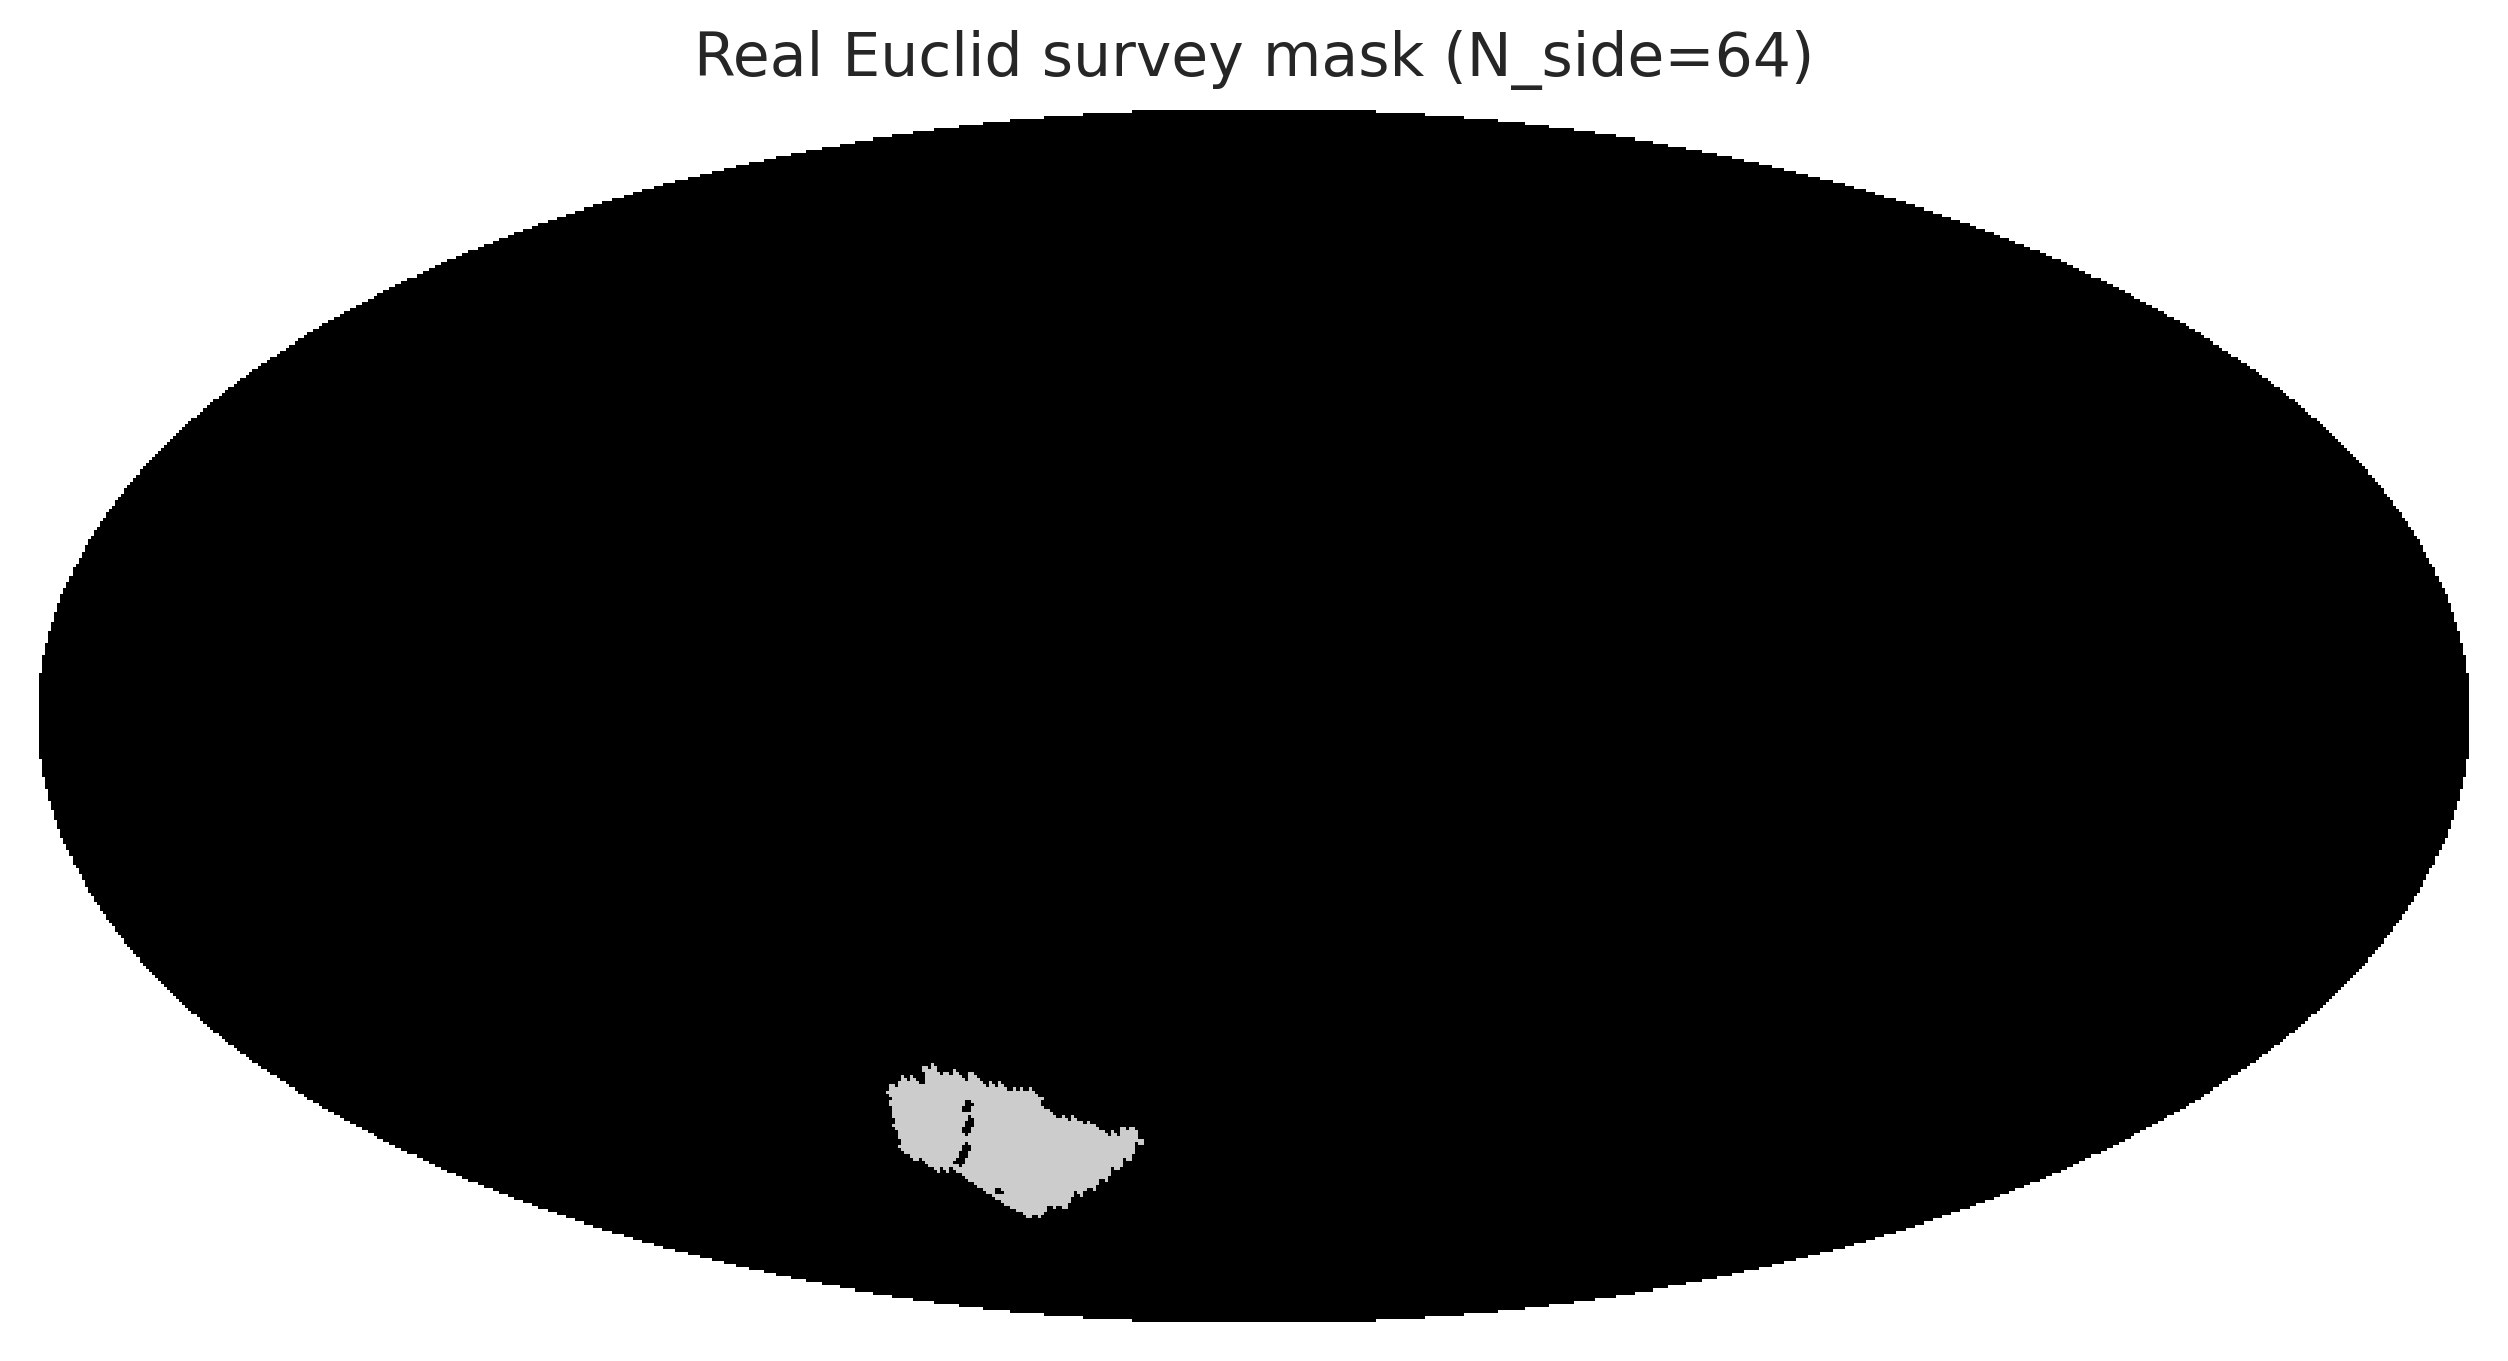

In [7]:
# Now plot this mask
plt.rcParams['text.usetex'] = False
hp.mollview(mask, cmap='nipy_spectral', cbar=False, title=f'Real Euclid survey mask (N_side={n_side})')
plt.show()

In [8]:
# Now save this mask to our TR1 data directory
mask_filepath = f'{tr1_data_dir}/masks/SkyMask_TR1_N{n_side}_cov{coverage_min:g}.fits'
hp.write_map(mask_filepath, mask.astype(float), overwrite=True, fits_IDL=False, dtype=np.float64)

### What the coverage cut removes

At $N_{\rm side}=64$ each pixel is about 55′ across, and many pixels along the edge of the survey are only partly covered. They hold few galaxies, so their noise is far above the single uniform noise variance the QML C++ assumes for every pixel (see the per-pixel noise plot further down). Pixels covered less than `coverage_min` are removed. Below: which pixels go, and where the cut sits in the distribution of covered fractions. Note that `coverage` and `mask` are full-sky HEALPix arrays (12·N_side² = 49,152 entries); the kept pixels are `mask.sum()`.

pixels with any coverage: 538;  kept (coverage >= 0.5): 442;  removed: 96 (18% of covered pixels, but only 5.2% of the covered area)


/tmp/ipykernel_86838/4291128579.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


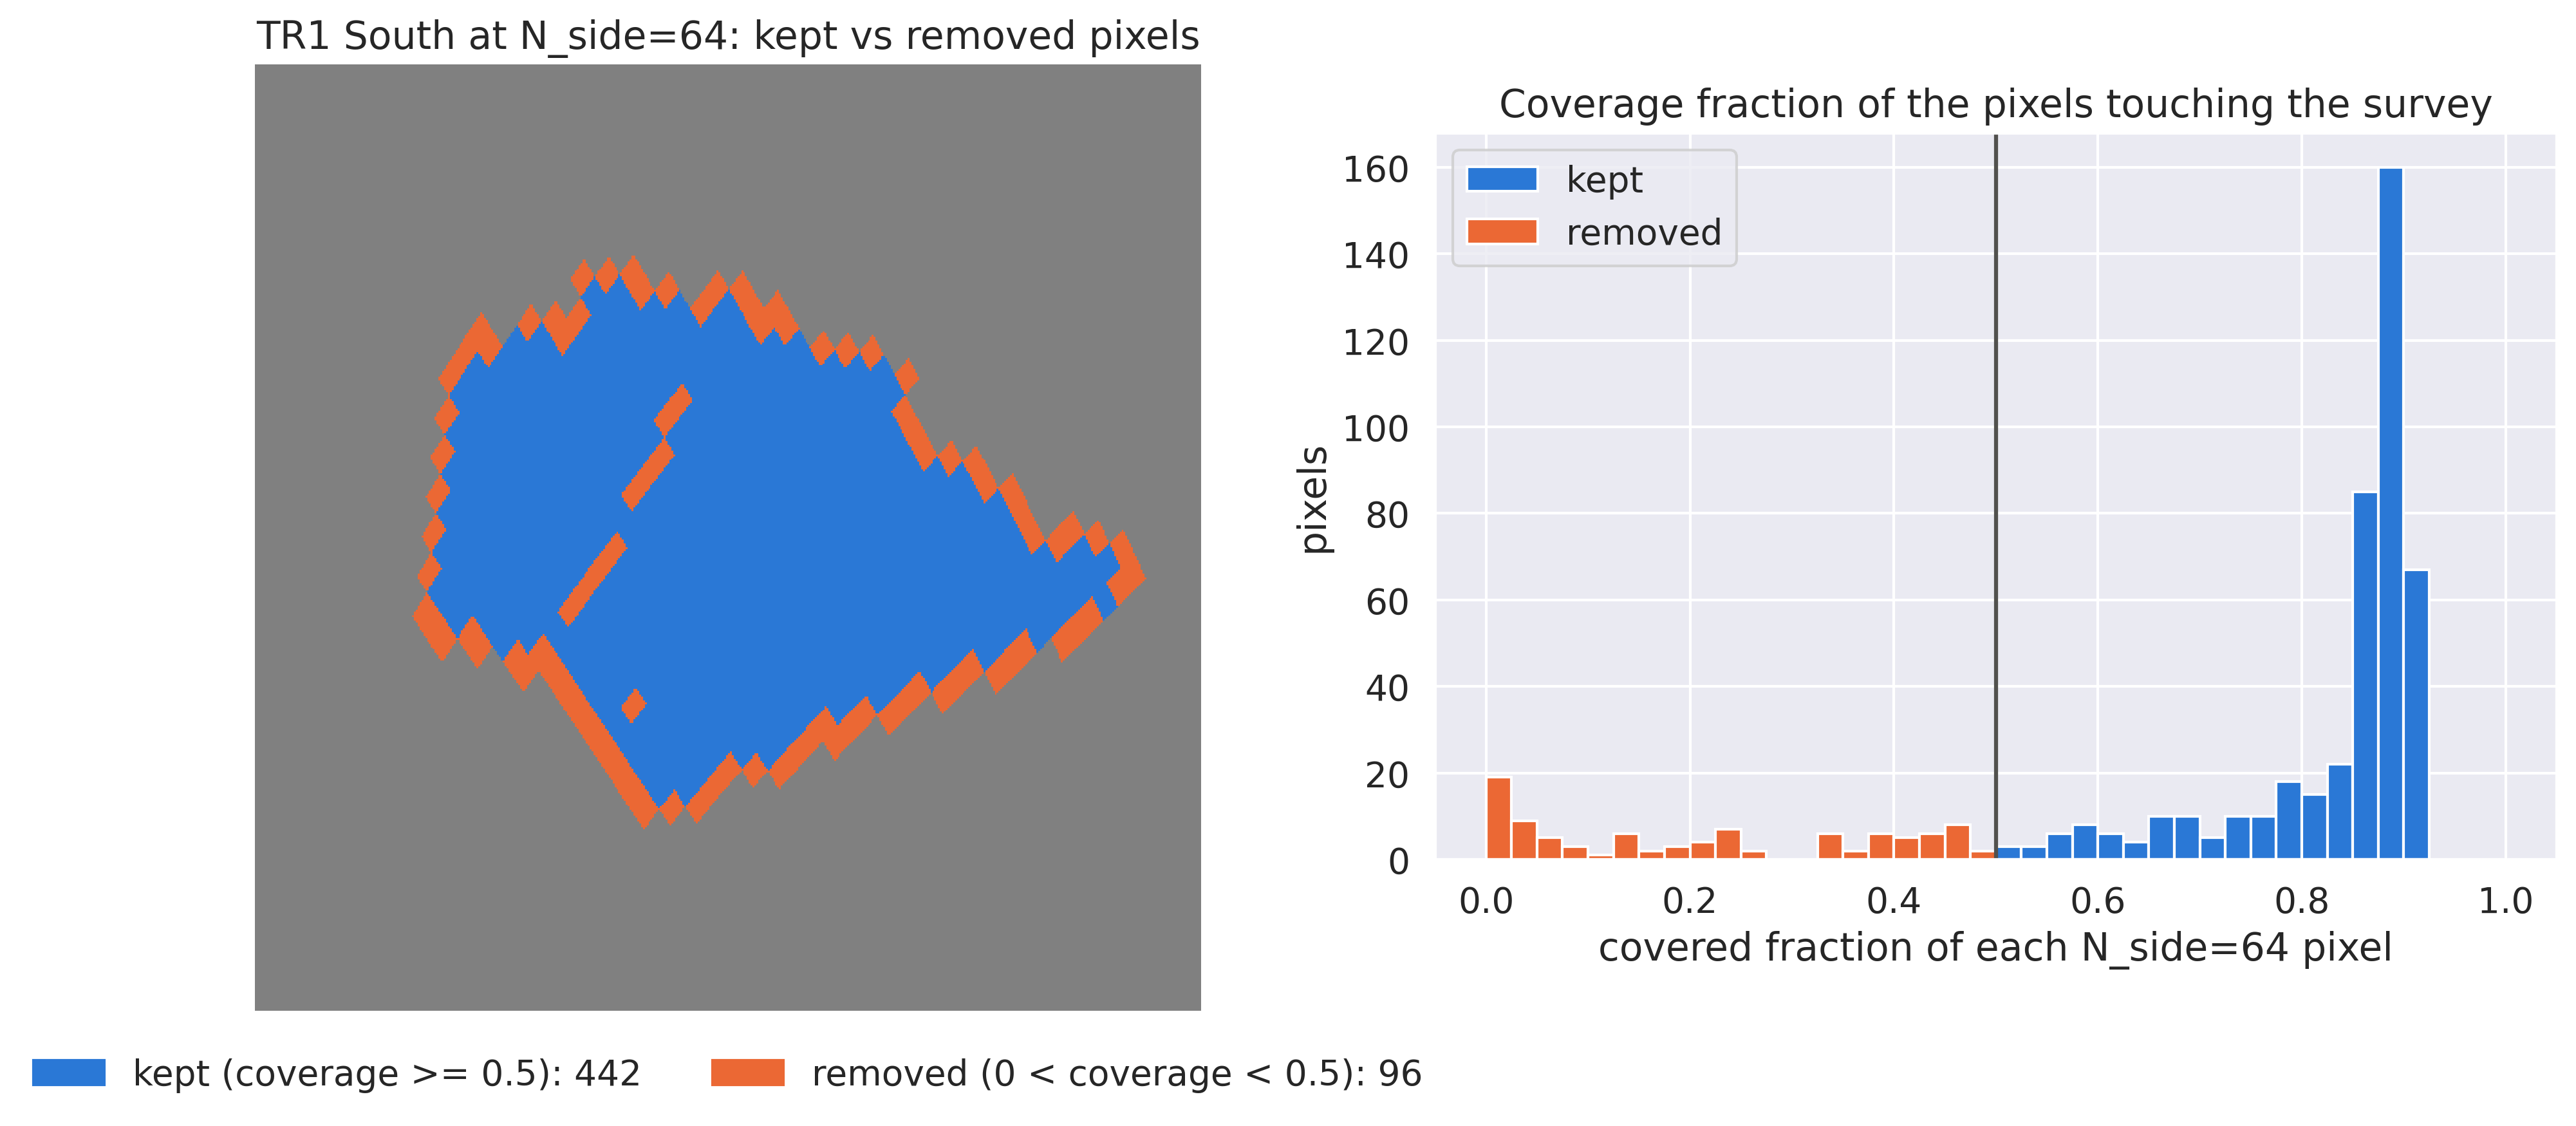

In [9]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

covered = coverage > 0
removed = covered & ~mask
print(f'pixels with any coverage: {covered.sum()};  kept (coverage >= {coverage_min:g}): {mask.sum()};  '
      f'removed: {removed.sum()} ({100 * removed.sum() / covered.sum():.0f}% of covered pixels, but only '
      f'{100 * coverage[removed].sum() / coverage[covered].sum():.1f}% of the covered area)')

# Centre and size of the patch, for a zoomed (gnomonic) view
vec = np.array(hp.pix2vec(n_side, np.where(covered)[0]))
centre = vec.mean(axis=1) / np.linalg.norm(vec.mean(axis=1))
radius_deg = np.degrees(np.arccos(np.clip(centre @ vec, -1, 1)).max())
lon_c, lat_c = hp.vec2ang(centre, lonlat=True)

state = np.full(coverage.size, hp.UNSEEN)
state[mask], state[removed] = 0, 1
fig = plt.figure(figsize=(13, 5))
hp.gnomview(state, rot=(lon_c[0], lat_c[0]), xsize=500, reso=2.4 * radius_deg * 60 / 500, fig=fig, sub=(1, 2, 1),
            cmap=ListedColormap(['#2a78d6', '#eb6834']), min=0, max=1, cbar=False, notext=True,
            title=f'TR1 South at N_side={n_side}: kept vs removed pixels')
plt.gca().legend(handles=[Patch(color='#2a78d6', label=f'kept (coverage >= {coverage_min:g}): {mask.sum()}'),
                          Patch(color='#eb6834', label=f'removed (0 < coverage < {coverage_min:g}): {removed.sum()}')],
                 loc='lower center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)

ax = fig.add_subplot(1, 2, 2)
bins_cov = np.linspace(0, 1, 41)
ax.hist(coverage[mask], bins=bins_cov, color='#2a78d6', label='kept')
ax.hist(coverage[removed], bins=bins_cov, color='#eb6834', label='removed')
ax.axvline(coverage_min, color='#52514e', lw=1.5)
ax.set_xlabel('covered fraction of each N_side=64 pixel'); ax.set_ylabel('pixels')
ax.set_title('Coverage fraction of the pixels touching the survey')
ax.legend()
plt.tight_layout()
plt.show()

## Bandpower binning

This survey patch is far too small to support unbinned per-$\ell$ QML/NaMaster estimates. With $f_\mathrm{sky}\approx0.9\%$, the number of independent sky modes at multipole $\ell$ is only $(2\ell+1) f_\mathrm{sky}$, and a ~20° patch can't resolve multipoles closer than $\Delta\ell\approx18$.

So we use **uniform bandpowers of width $\Delta\ell=20$** from $\ell=10$. (The north notebook's equal-modes binning gave bands only 5–7 multipoles wide at high $\ell$. That's narrower than the resolution, so neighbouring QML bands were strongly anticorrelated and alternated in sign.) The binning matrix is applied to the QML Fisher matrix and $y_\ell$ values *before* inverting, rather than inverting the near-singular unbinned Fisher matrix and binning afterwards. The same bin edges are used for NaMaster and heracles, so all three pipelines are compared on one $\ell$ grid.

In [10]:
bandpower_width = 20
ells_for_binning = np.arange(10, l_max_full + 1)
modes_per_ell = (2 * ells_for_binning + 1) * f_sky

# Uniform-width bands, at least as wide as the patch's multipole resolution (~2*pi/theta ~ 18 for a ~20 deg patch).
# Narrower bands (the equal-modes scheme gave 5-7 multipoles at high l) can't be separated by this mask: neighbouring
# QML bandpowers become almost perfectly anticorrelated (down to -0.92) and alternate in sign by several sigma.
# The last band absorbs the remainder so it is never narrower than bandpower_width.
ell_bp_edges = np.r_[np.arange(10, l_max_full + 1 - bandpower_width, bandpower_width), l_max_full + 1]
ell_bp_ini = ell_bp_edges[:-1]
ell_bp_end = ell_bp_edges[1:]
n_bands = len(ell_bp_ini)

# Binning (Jacobian) matrix mapping the unbinned ells_full grid onto our bandpowers.
# For a flat bandpower model (C_ell = C_b for ell in bin b), d(C_ell)/d(C_b) = 1, so this
# must be an unweighted 0/1 indicator - NOT a 1/N average - since it is applied as the
# congruence transform on the Fisher matrix (F_b = W^T F W) and as a plain sum on y_ell
# (y_b = W^T y). Using a 1/N-normalised matrix on both sides (as before) silently inflates
# the recovered C_b by an extra factor of N_b (the number of raw ells in that bin).
bin_matrix = np.zeros((n_bands, n_ell_full))
for b in range(n_bands):
    in_bin = (ells_full >= ell_bp_ini[b]) & (ells_full < ell_bp_end[b])
    bin_matrix[b, in_bin] = 1.0

# Block-diagonal version (EE then BB) used to bin the QML Fisher matrix/y_ell values
bin_matrix_EB = np.zeros((2 * n_bands, 2 * n_ell_full))
bin_matrix_EB[0: n_bands, 0: n_ell_full] = bin_matrix
bin_matrix_EB[n_bands: 2 * n_bands, n_ell_full: 2 * n_ell_full] = bin_matrix

# NaMaster bandpower object, built from the same bin edges, so QML and NaMaster share ells
bins = nmt.NmtBin.from_edges(ell_bp_ini, ell_bp_end)
ell_bp = bins.get_effective_ells()


In [11]:
l_max_full

150

## Compute and save the fiducial power spectrum

As the QML estimator requires an estimate for the power spectrum of the maps that wish to be processed, we need to compute and save it to the disk here.

Here, we use the Core Cosmology Library (CCL) to compute this.

We also need to specify the redshift range of sources in our analysis. Rather than assuming a fixed Gaussian centred at $z=1.0$ for every tomographic bin, we measure the (weighted) photo-z distribution directly from the real shear catalogue for our chosen bin - the six TR1 tomographic bins span very different redshifts (bin 1 medians around $z \approx 0.38$, bin 6 around $z \approx 1.8$), so a single fixed $z=1.0$ dndz badly mismatches the lensing efficiency/amplitude for most bins, which was the main cause of the large gap between the fiducial model and the heracles/QML/PCl measurements.

Note: since we don't know the true cosmology of the real TR1 data, this is only used as a fiducial/proxy spectrum to precondition and weight the QML estimator - it does not need to exactly match the real data for the estimator to remain valid (just to be reasonably close, for near-optimal error bars).

In [12]:
# First set up some fiducial cosmology values
fiducial_cosmology = {'h': 0.7, 'Omega_c': 0.27, 'Omega_b': 0.045, 'sigma8': 0.75, 'n_s': 0.96,
                      'm_nu': 0.0, 'T_CMB': 2.7255, 'w0': -1.0, 'wa': 0.0}

# Read the catalogue columns needed both here (photo-z) and below (ellipticities/weights/
# positions), once. Every tomographic bin is kept (no TOM_BIN_ID filter) so that all bins
# are combined into a single, higher-density sample (see the configuration cell above).
she_cols = ['SHE_RA', 'SHE_DEC', 'SHE_E1_CORRECTED', 'SHE_E2_CORRECTED', 'SHE_WEIGHT', 'PHZ_MEDIAN', 'TOM_BIN_ID']
she_data = fitsio.read(she_catalog_filepath, columns=she_cols)

she_weight = she_data['SHE_WEIGHT'].astype(np.float64)

# Redshift distribution measured directly from the combined (weighted) photo-z estimates of
# every bin, rather than a fixed Gaussian or a single bin's own n(z)
z_edges = np.linspace(0.0, 3.0, 501)
redshift_range = (z_edges[:-1] + z_edges[1:]) / 2
redshift_dist, _ = np.histogram(she_data['PHZ_MEDIAN'], bins=z_edges, weights=she_weight)

# Output file path
cl_file_path = f'{tr1_data_dir}/TheorySpectra_TR1_N{n_side}_cov{coverage_min:g}.dat'

# Set up our PowerSpec class and compute the theory spectra
pow_spec = PowerSpec(n_side, fiducial_cosmology, redshift_range, redshift_dist, cl_file_path)

pow_spec.compute_power_spec()

Evaluating the theory Cl values using CCL


Saved the power spectrum to /home/vscode/WeakLensingQML/TR1/data/south/TheorySpectra_TR1_N64_cov0.5.dat


As the intrinsic ellipticity of galaxies introduces a shot-noise term to the cosmic shear power spectrum, we need to estimate it here. Rather than assuming fiducial values, we measure the (weighted) intrinsic ellipticity dispersion and effective galaxy number density directly from the real shear catalogue, for our chosen tomographic bin.

In [13]:
# she_data/she_weight were already read above (alongside the photo-z distribution), now
# combined across all tomographic bins
she_e1 = -she_data['SHE_E1_CORRECTED'].astype(np.float64)  # Sign matches the pipeline's SHE field definition
she_e2 = she_data['SHE_E2_CORRECTED'].astype(np.float64)

# Only galaxies in kept (unmasked) pixels count towards the noise level: the area and pixel count below are
# those of the kept mask, so including galaxies from removed edge pixels would overstate the density (by ~5%
# for South at coverage_min = 0.5) and understate the QML noise_var
in_mask = mask[hp.ang2pix(n_side, she_data['SHE_RA'], she_data['SHE_DEC'], lonlat=True)]
w_in = she_weight[in_mask]
print(f'{in_mask.sum():,} of {len(in_mask):,} galaxies are in kept pixels')

# Weighted per-component intrinsic ellipticity dispersion, measured directly from the catalogue
sigma_e2 = np.sum(w_in * (she_e1[in_mask] ** 2 + she_e2[in_mask] ** 2)) / (2 * np.sum(w_in))

# Effective number of galaxies, combined across all tomographic bins (accounts for weight variance)
n_eff = np.sum(w_in) ** 2 / np.sum(w_in ** 2)

# Sky area covered by our real mask, in steradians
area_mask = mask.sum() / mask.size * 4 * np.pi

# Average galaxy density over the unmasked footprint, in galaxies/arcmin^2
arcmin2_per_steradian = (180 / np.pi) ** 2 * 3600
avg_gal_den = n_eff / (area_mask * arcmin2_per_steradian)
print(f'Average galaxy density: {avg_gal_den:.3f} galaxies/arcmin^2')

# Theory noise power spectrum (shot-noise), in the same units as pow_spec.cl_EE
cl_noise = sigma_e2 / (n_eff / area_mask)

# Average effective number of galaxies per unmasked HEALPix pixel, and the associated
# map-domain per-pixel noise variance required by the QML C++ code
num_gal_per_pix = n_eff / mask.sum()
noise_var = sigma_e2 / num_gal_per_pix
print(num_gal_per_pix)
print(noise_var)

29,450,427 of 31,022,277 galaxies are in kept pixels
Average galaxy density: 21.929 galaxies/arcmin^2
66258.8863322232
1.6851078984916374e-06


## Quickly plot the power spectra

Now just plot the saved power spectra 

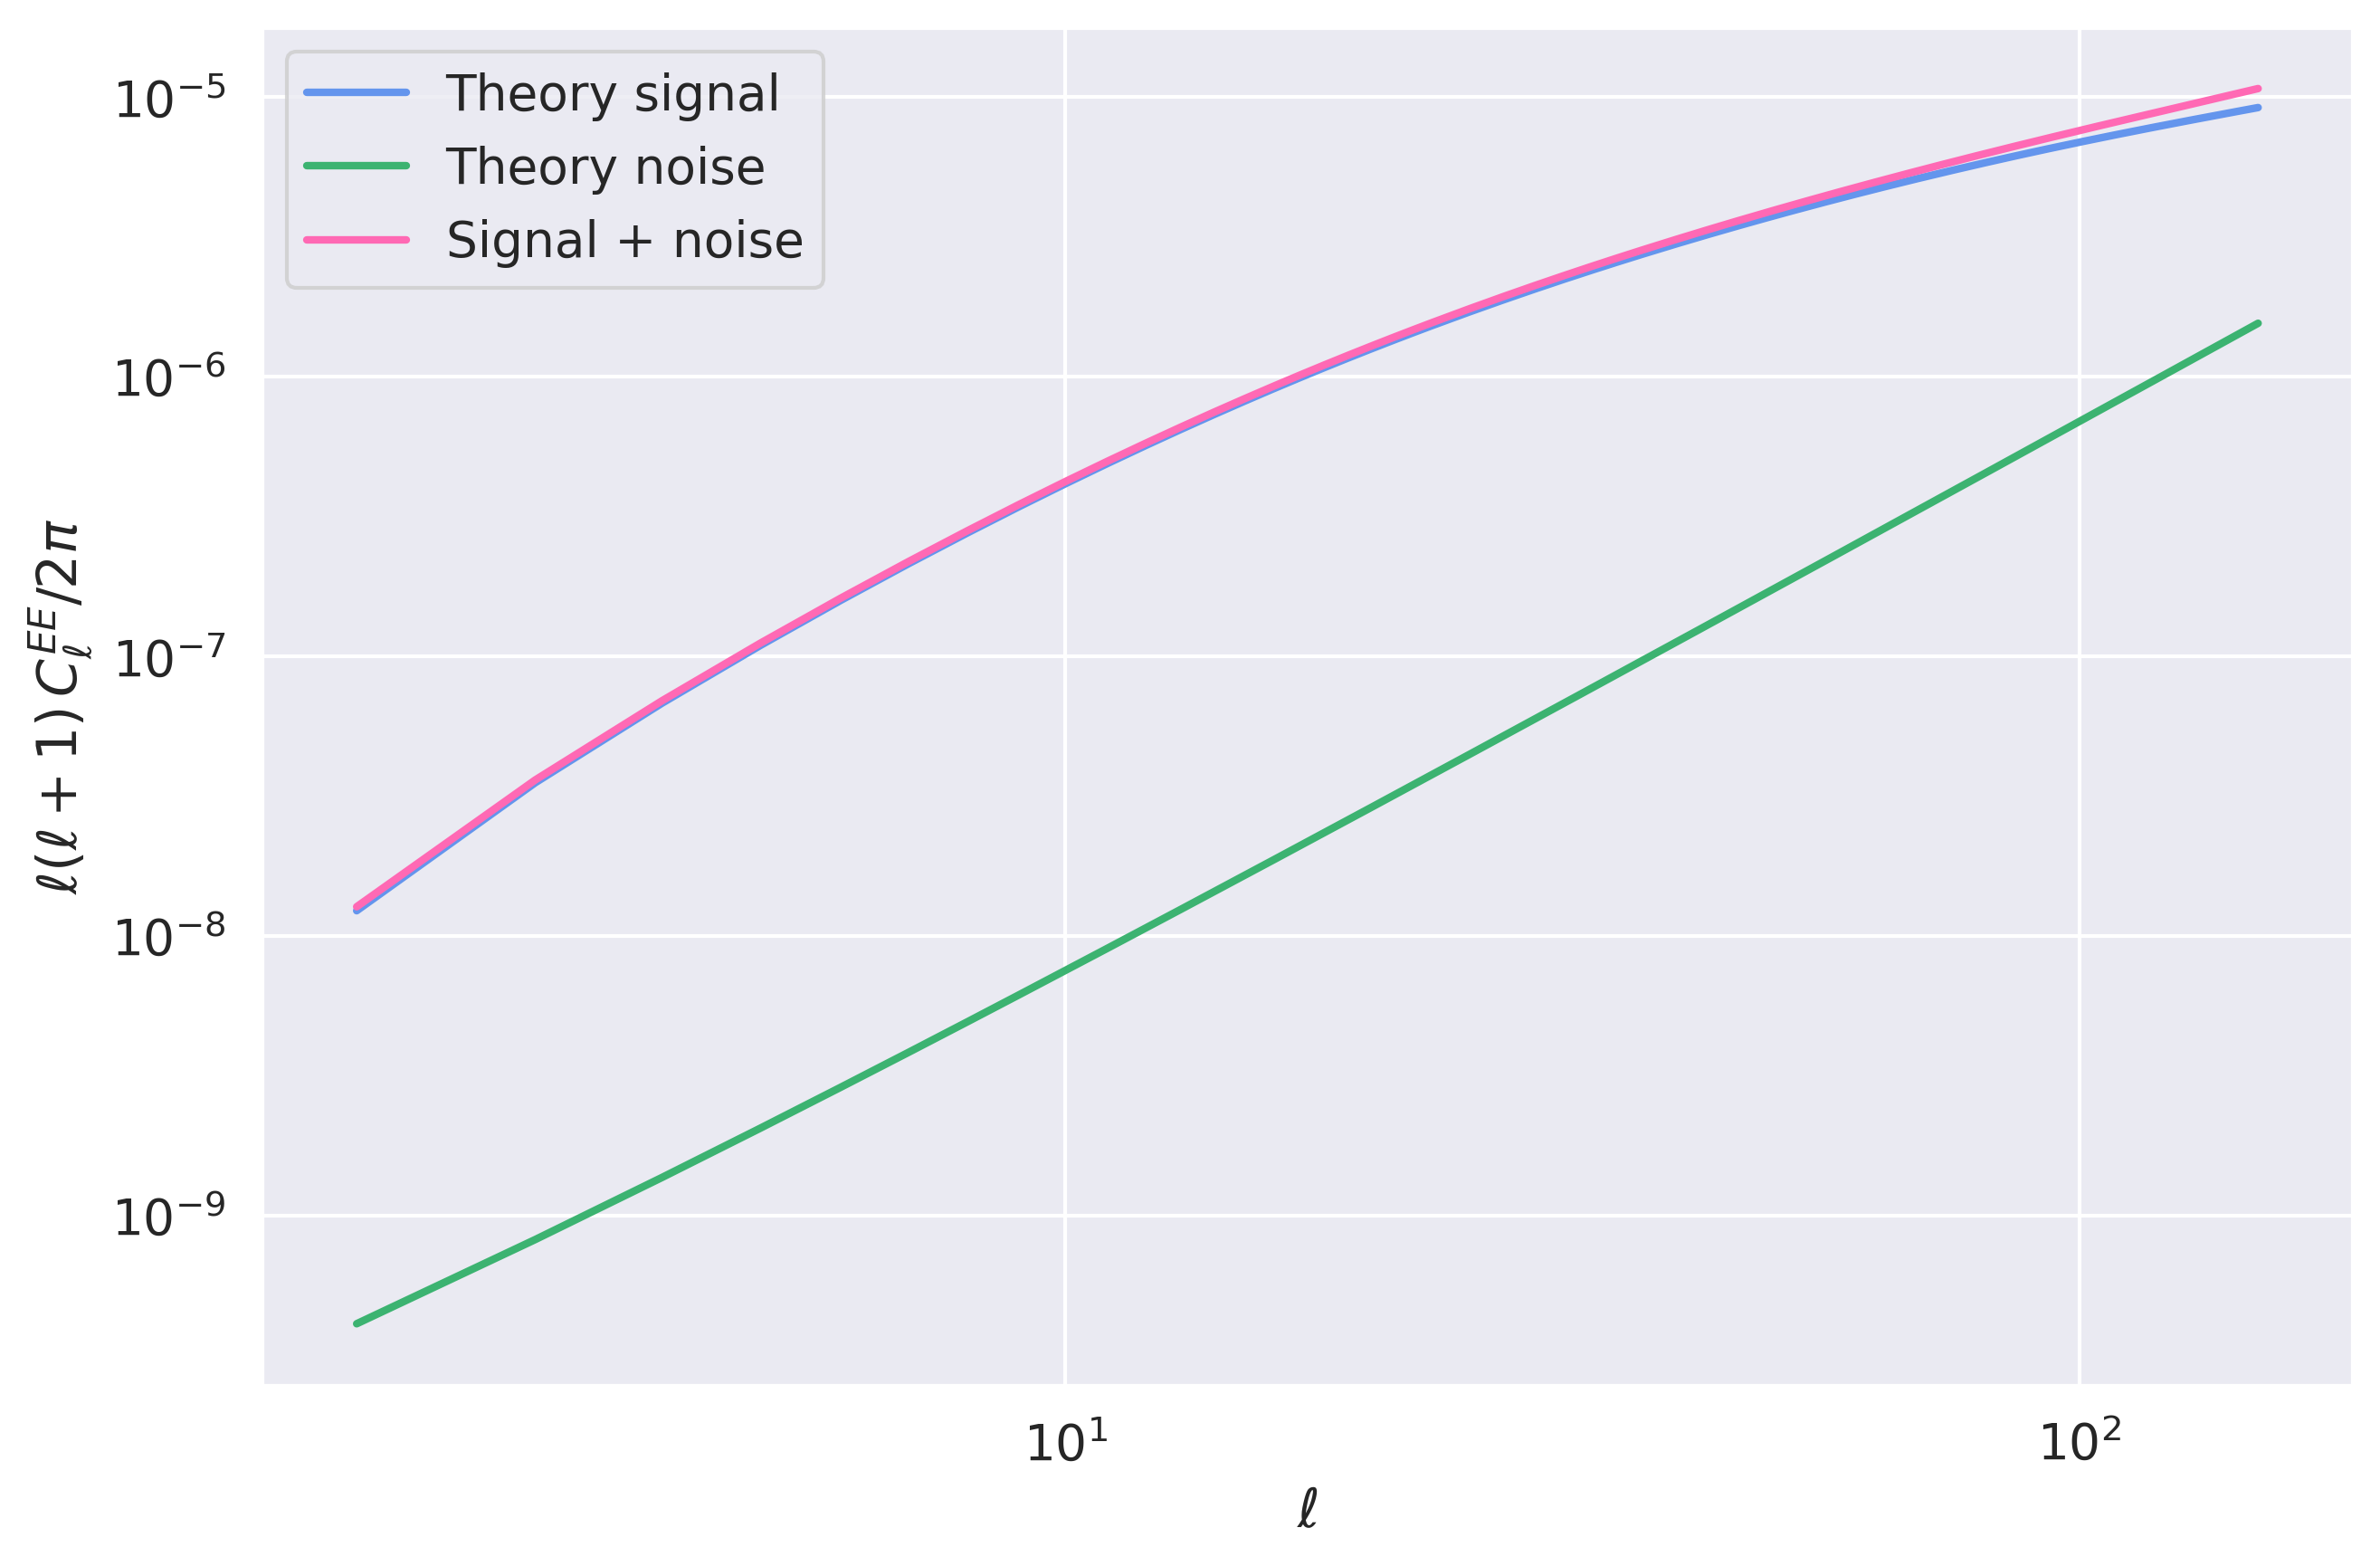

In [14]:
fix, ax = plt.subplots(figsize=(9, 6))

ax.loglog(ells, ells * (ells + 1) * pow_spec.cl_EE[2: l_max + 1] / (2 * np.pi), lw=2, c='cornflowerblue', label='Theory signal')
ax.loglog(ells, ells * (ells + 1) * cl_noise / (2 * np.pi), lw=2, c='mediumseagreen', label='Theory noise')
ax.loglog(ells, ells * (ells + 1) * (pow_spec.cl_EE[2: l_max + 1] + cl_noise) / (2 * np.pi), lw=2, c='hotpink', label='Signal + noise')

ax.set_xlabel(r'$\ell$')
ax.set_ylabel(r'$\ell (\ell + 1) \, C_{\ell}^{EE} / 2 \pi$')

ax.legend()

plt.tight_layout()
plt.show()

## Build the real shear (gamma1, gamma2) maps from the Euclid catalogue

Instead of a mock Gaussian simulation, we now pixelise the real shear catalogue (for our chosen tomographic bin) onto a HEALPix map at our QML resolution. This is the map whose power spectrum we want to estimate with the QML and NaMaster (PCl) methods, and compare against heracles' own pipeline output.

In [15]:
# Pixelise the real shear catalogue (all tomographic bins combined) onto a HEALPix map
she_ra = she_data['SHE_RA'].astype(np.float64)
she_dec = she_data['SHE_DEC'].astype(np.float64)

she_pix = hp.ang2pix(n_side, she_ra, she_dec, lonlat=True)

sum_weight = np.zeros(n_pix)
sum_weight_e1 = np.zeros(n_pix)
sum_weight_e2 = np.zeros(n_pix)

np.add.at(sum_weight, she_pix, she_weight)
np.add.at(sum_weight_e1, she_pix, she_weight * she_e1)
np.add.at(sum_weight_e2, she_pix, she_weight * she_e2)

# Weighted average shear per pixel (left as zero where there are no galaxies)
map_gamma1 = np.divide(sum_weight_e1, sum_weight, out=np.zeros(n_pix), where=sum_weight > 0)
map_gamma2 = np.divide(sum_weight_e2, sum_weight, out=np.zeros(n_pix), where=sum_weight > 0)

# Now apply our real survey mask
map_gamma1 *= mask
map_gamma2 *= mask

# Save the shear maps to disk for the QML C++ code
map_gamma1_path = f'{tr1_data_dir}/Map_TR1_N{n_side}_cov{coverage_min:g}_gamma1.fits'
map_gamma2_path = f'{tr1_data_dir}/Map_TR1_N{n_side}_cov{coverage_min:g}_gamma2.fits'

hp.write_map(map_gamma1_path, map_gamma1, overwrite=True, fits_IDL=False, dtype=np.float64)
hp.write_map(map_gamma2_path, map_gamma2, overwrite=True, fits_IDL=False, dtype=np.float64)

### Per-pixel noise: why the partly covered pixels have to go

The real noise variance of each pixel's weighted mean shear is $\sigma_\epsilon^2\sum w^2/(\sum w)^2$. QML assumes one value, `noise_var`, for every pixel. The plot shows the ratio for every covered pixel against its covered fraction. Partly covered pixels have far fewer galaxies, so their noise is many times the assumed value; kept in the mask, that unmodelled variance biases every QML bandpower.

    kept:  442 pixels; real/assumed noise variance: median 0.98, mean 1.02, max 1.7
 removed:   95 pixels; real/assumed noise variance: median 4.24, mean 238.75, max 13,342.5
galaxies removed: 1,571,850 (5.1% of the catalogue)


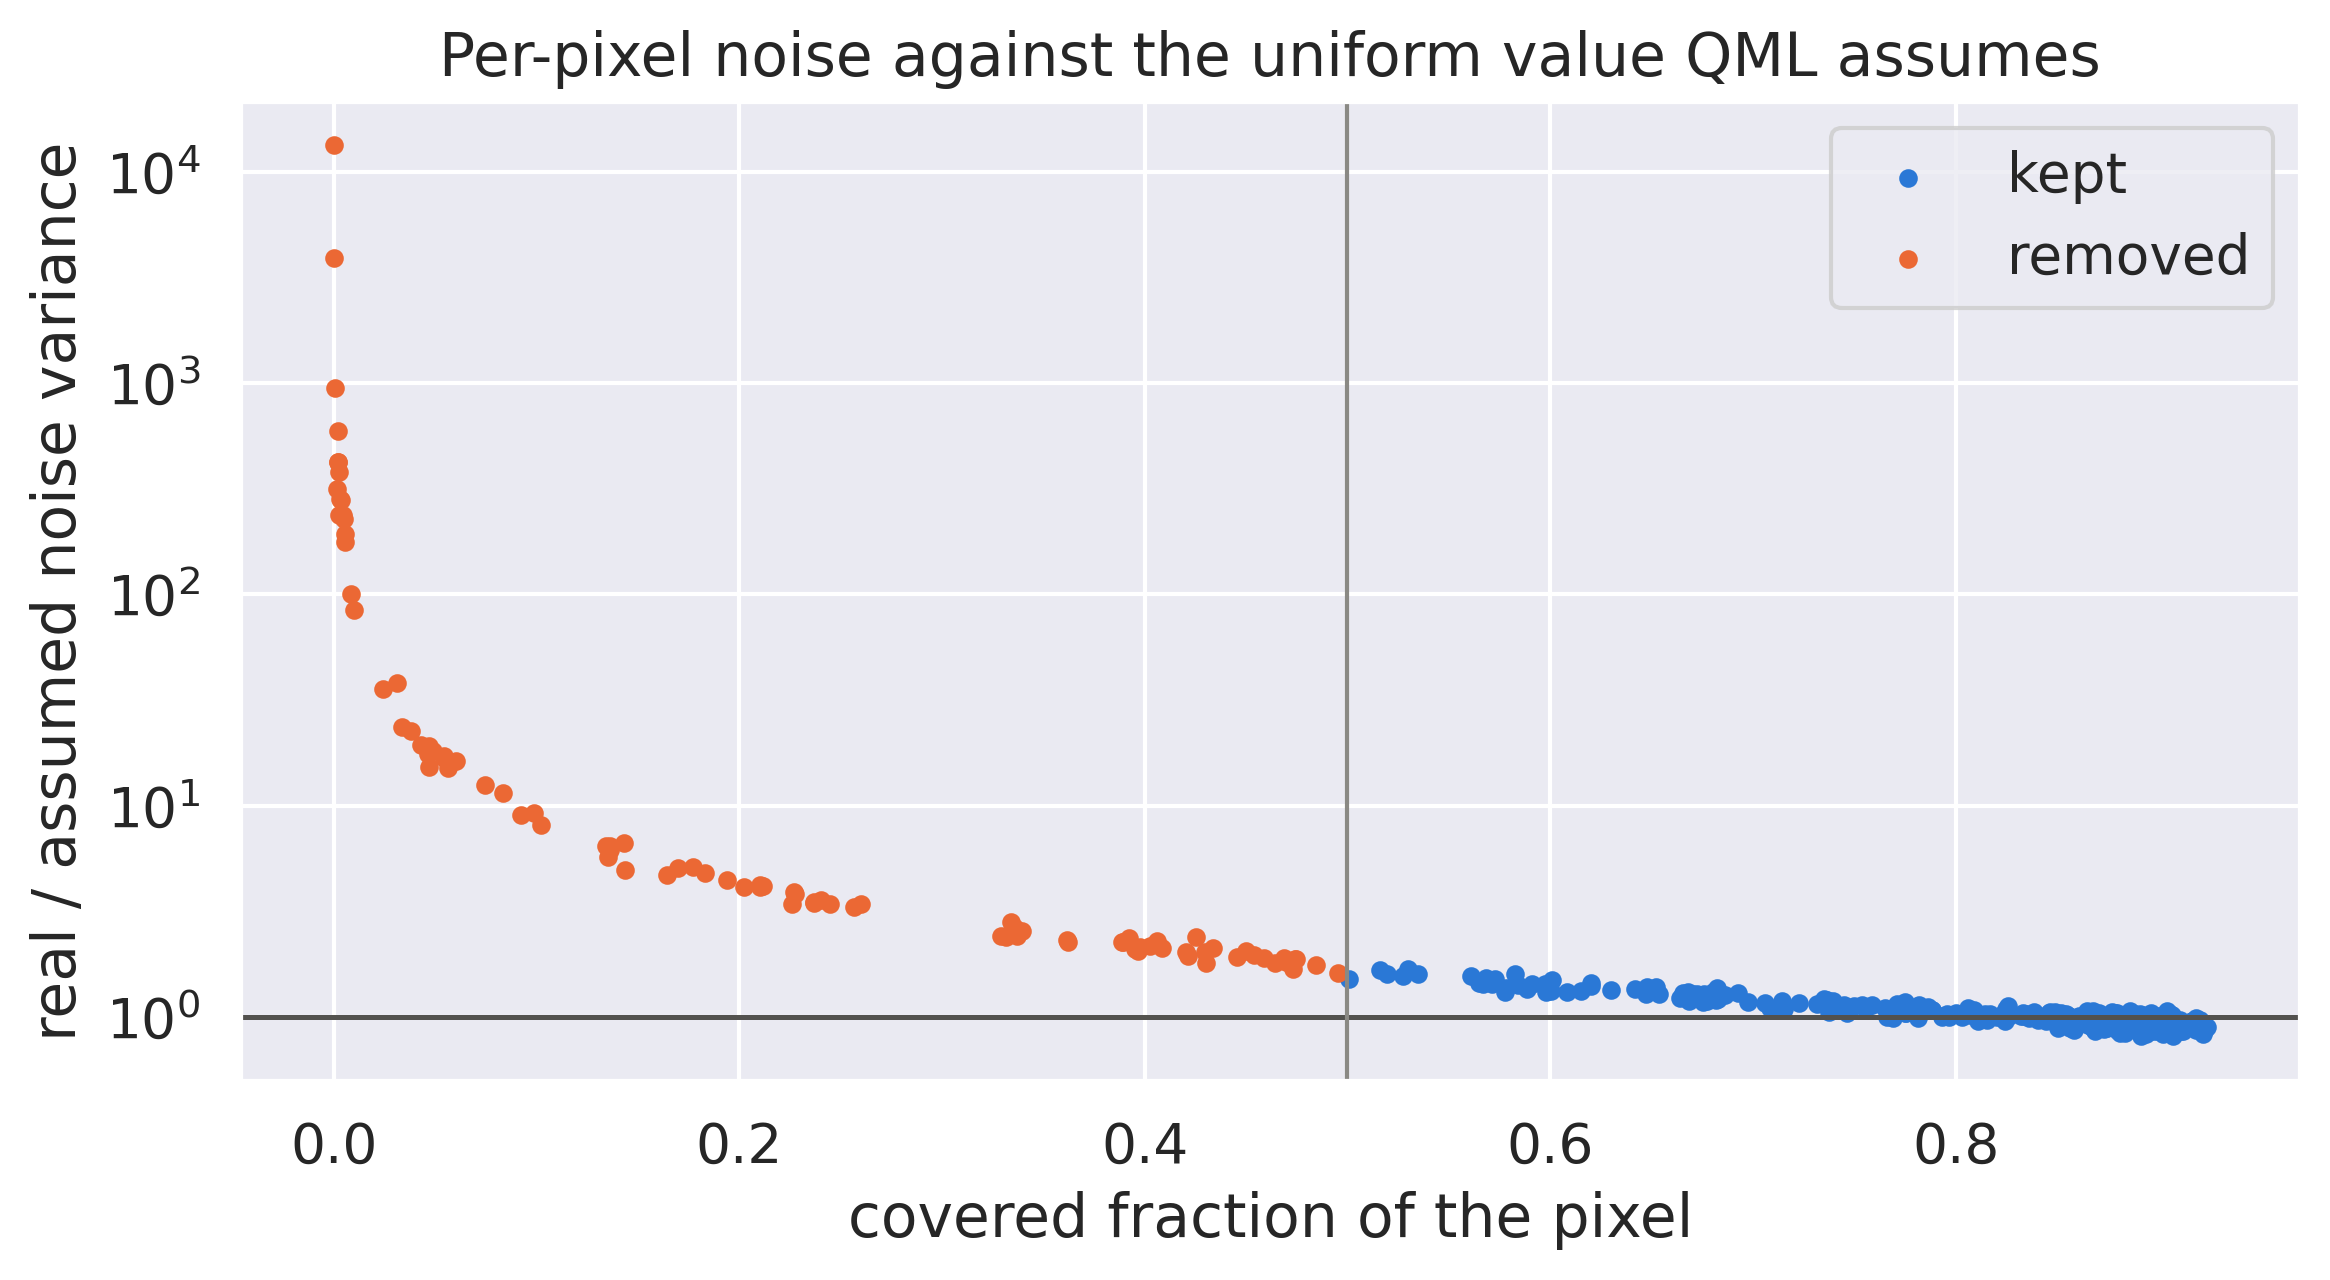

In [16]:
sum_weight2 = np.zeros(n_pix)
np.add.at(sum_weight2, she_pix, she_weight ** 2)
has_gal = sum_weight > 0
pixel_noise = np.full(n_pix, np.nan)
pixel_noise[has_gal] = sigma_e2 * sum_weight2[has_gal] / sum_weight[has_gal] ** 2
noise_ratio = pixel_noise / noise_var

for label, sel in [('kept', mask & has_gal), ('removed', removed & has_gal)]:
    print(f'{label:>8}: {sel.sum():4d} pixels; real/assumed noise variance: median {np.median(noise_ratio[sel]):.2f}, '
          f'mean {noise_ratio[sel].mean():.2f}, max {noise_ratio[sel].max():,.1f}')
w_removed = she_weight[removed[she_pix]]
print(f'galaxies removed: {len(w_removed):,} ({100 * len(w_removed) / len(she_weight):.1f}% of the catalogue)')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(coverage[mask & has_gal], noise_ratio[mask & has_gal], s=12, color='#2a78d6', label='kept')
ax.scatter(coverage[removed & has_gal], noise_ratio[removed & has_gal], s=12, color='#eb6834', label='removed')
ax.axhline(1, color='#52514e', lw=1.2)
ax.axvline(coverage_min, color='#8a8984', lw=1)
ax.set_yscale('log')
ax.set_xlabel('covered fraction of the pixel'); ax.set_ylabel('real / assumed noise variance')
ax.set_title('Per-pixel noise against the uniform value QML assumes')
ax.legend()
plt.tight_layout()
plt.show()

We can now plot our real cosmic shear map!

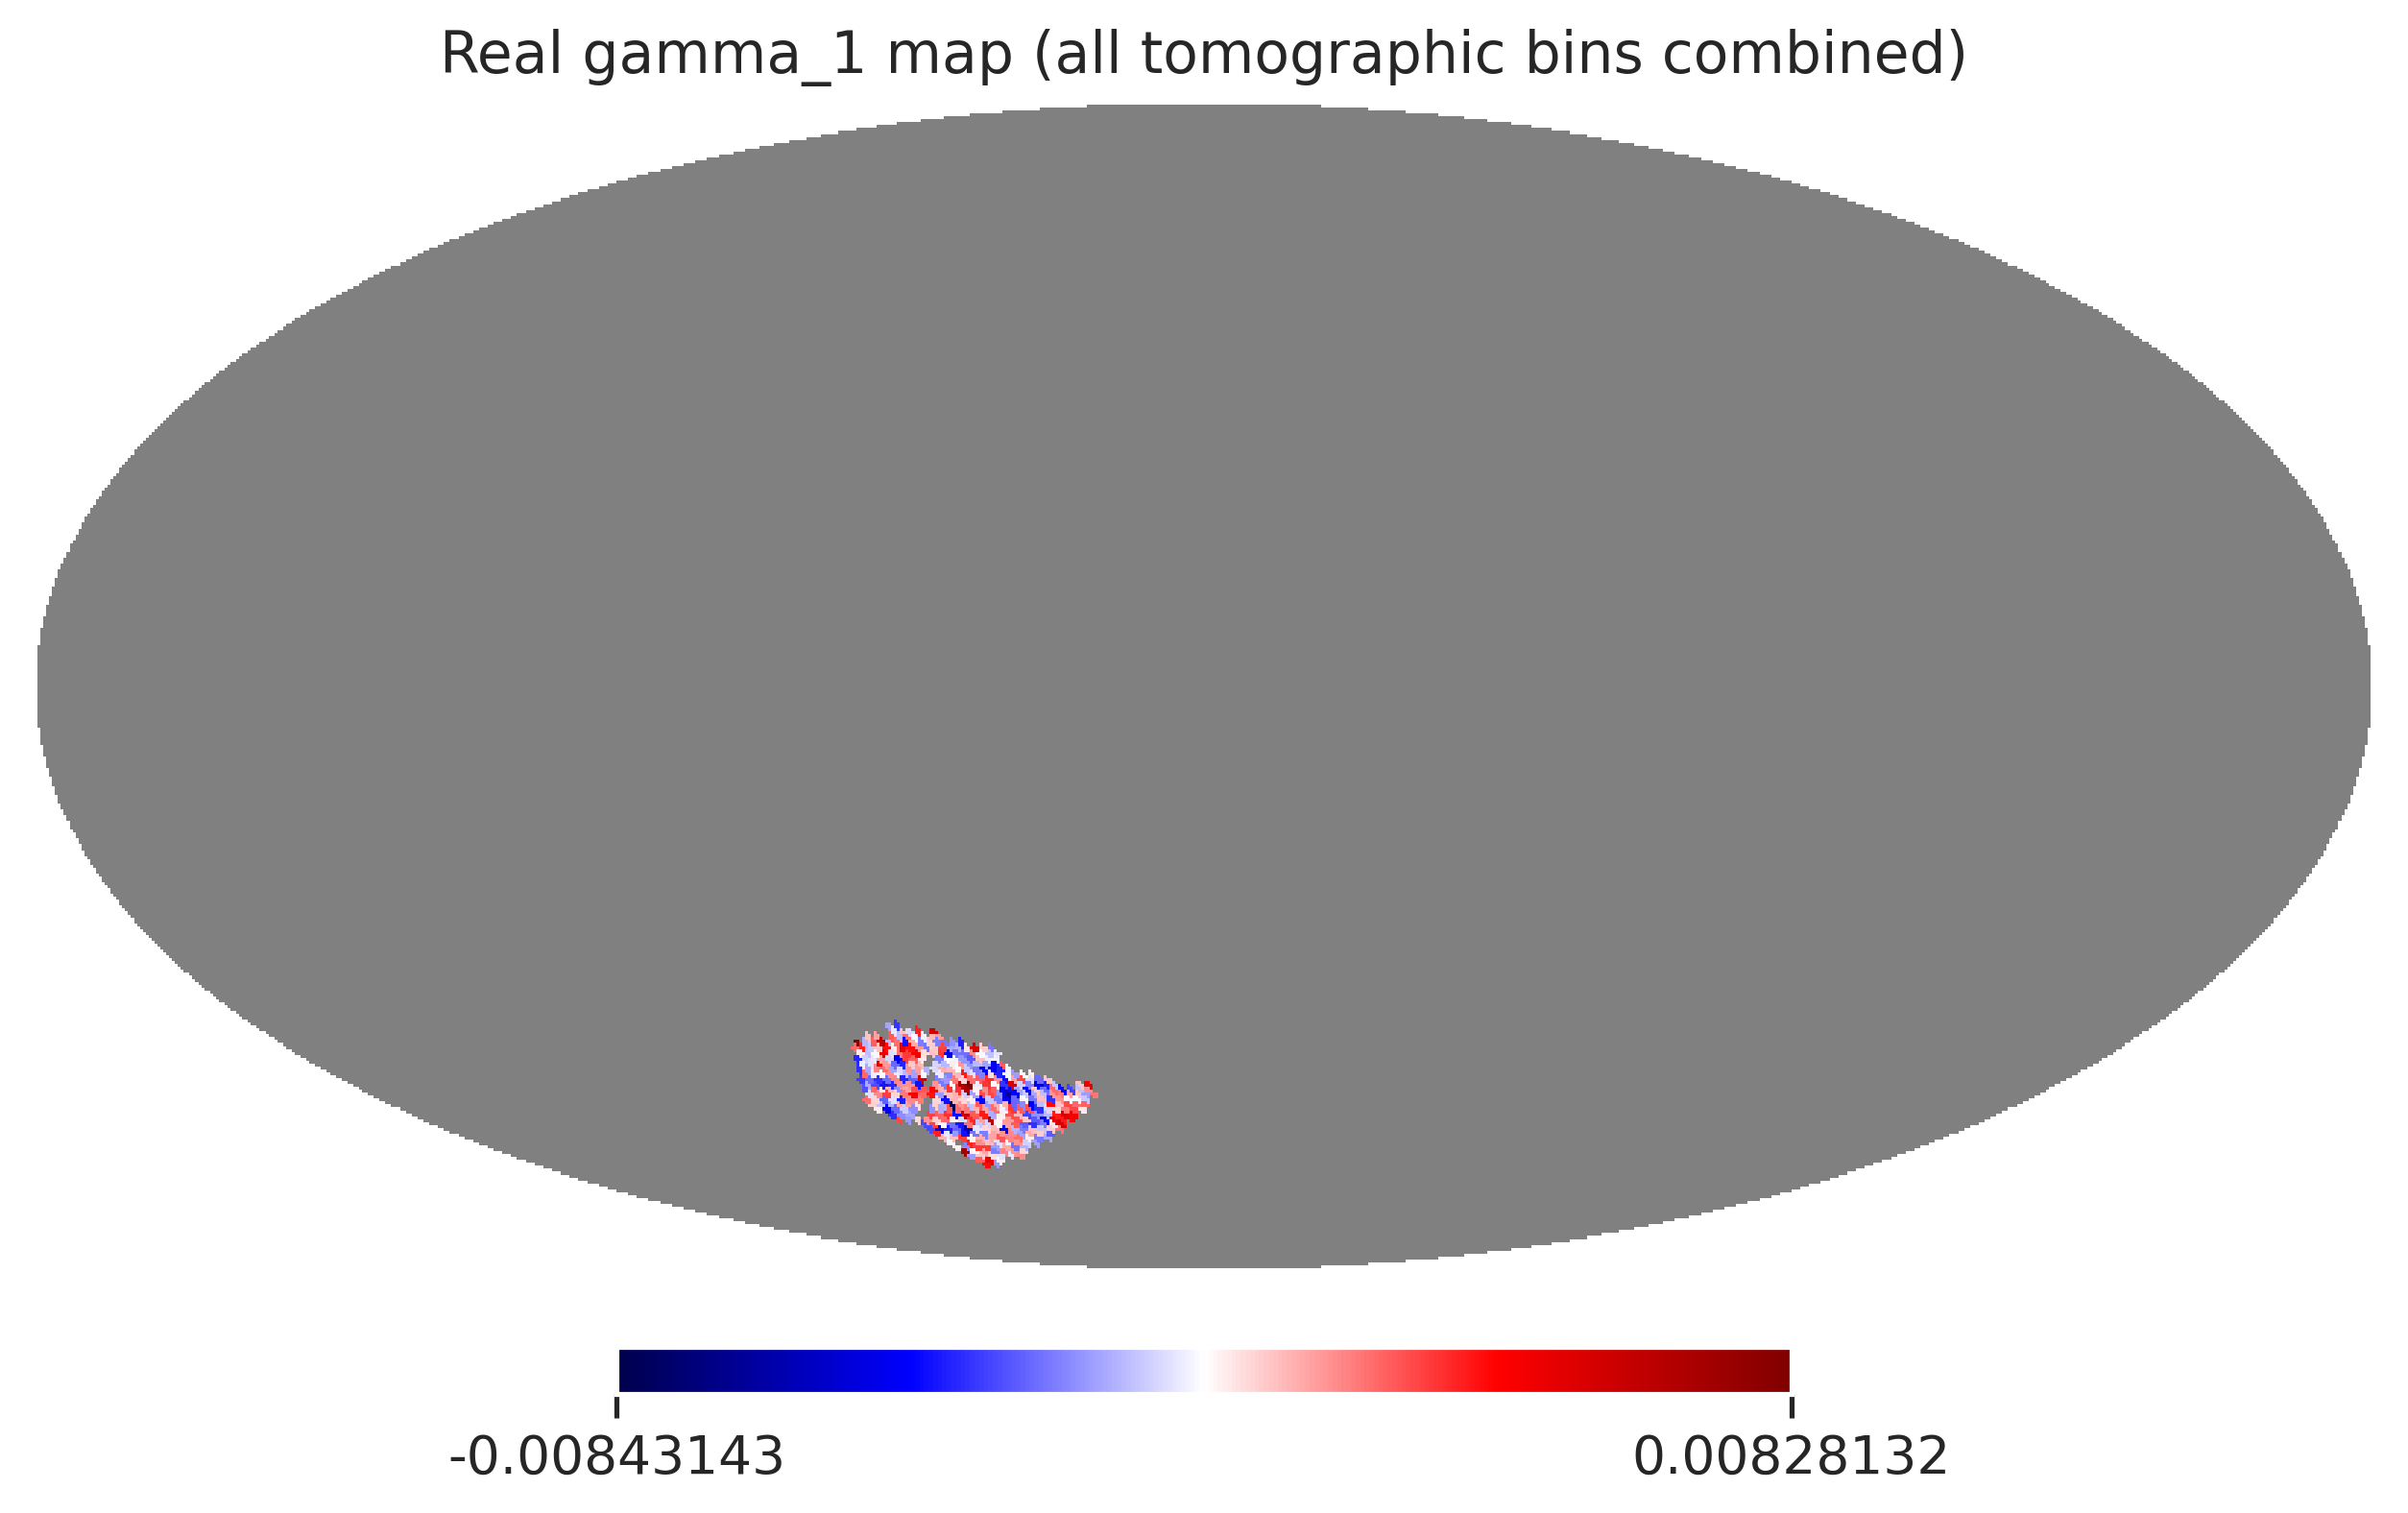

In [17]:
plot_map_gamma1 = map_gamma1.copy()
plot_map_gamma1[plot_map_gamma1 == 0] = np.nan

plt.rcParams['text.usetex'] = False
hp.mollview(plot_map_gamma1, cmap='seismic', cbar=True, title='Real gamma_1 map (all tomographic bins combined)')

## Load in the C++ library

We now need to load in the C++ library which contains the core QML algorithm for both estimating the covariance matrix and using that to estimate the power spectrum of our masked map.

The `num_maps` parameter determines how many maps we should average over when computing the estimate for the Fisher
matrix. The more maps the more accurate the final estimation will be, though with fewer maps the results will be unbiased. Please check our reference paper for a detailed discussion of this topic.

In [18]:
num_maps = 10  # increased from 5 now that n_side/l_max_full are set for a real run, not just a timing test

In [19]:
# First, generate the "constants.h" file that is necessary for the C++ code to compile (and thus run)
# l_max_full is passed explicitly since it is decoupled from n_side (see the discussion above
# about why this small real mask cannot support unbinned per-ell estimates up to 3*n_side-1)

# Reload in case this module was imported before generate_constants_h gained the l_max argument
import importlib
from python.lib.CppInterface import GenerateCppConstants
importlib.reload(GenerateCppConstants)
from python.lib.CppInterface.GenerateCppConstants import generate_constants_h

# Private copy of the C++ source for South, so the shared cpp/detail/constants.h is never touched
import shutil
cpp_dir = f'{tr1_data_dir}/cpp'
shutil.copytree(f'{root_filepath}/cpp', cpp_dir, dirs_exist_ok=True, ignore=shutil.ignore_patterns('build*'))

generate_constants_h(n_side, mask, noise_var, num_maps, f'{cpp_dir}/detail/constants.h', l_max=l_max_full)

Now compile the private C++ copy against the `constants.h` just generated (a release build in `TR1/data/south/cpp/build-release`).

In [20]:
import os
import subprocess

build_dir = f'{cpp_dir}/build-release'
subprocess.run(['cmake', '-S', cpp_dir, '-B', build_dir, '-DCMAKE_BUILD_TYPE=Release'], check=True, capture_output=True)
subprocess.run(['cmake', '--build', build_dir, '--target', 'QMLShearLib', '-j'], check=True, capture_output=True)

lib_path = f'{build_dir}/libQMLShearLib.so'
print('Built', lib_path)

Built /home/vscode/WeakLensingQML/TR1/data/south/cpp/build-release/libQMLShearLib.so


Now load in the library

In [21]:
cpp_lib = CppLib(lib_path, mask_filepath, cl_file_path)

## Compute Fisher matrix

With our C++ library loaded, we can now compute and save the estimated Fisher matrix for our QML estimator for our mask and power spectrum

In [22]:
fisher_matrix_out = f'{tr1_data_dir}/Fisher_matrix_TR1_south_N{n_side}_lmax{l_max_full}_maps{num_maps}_cov{coverage_min:g}_nv{noise_var:.4e}.dat'

Do note that for map resolutions greater than `N_side` of about 64, the computation of the Fisher matrix can take a seriously long time!

For example, a run at `N_side = 64` using 16 cores took about 45 minutes, so be prepared for some long run-times!

In [23]:
# Reuse a Fisher matrix already computed with the same settings (the filename encodes n_side, l_max and num_maps)
if os.path.exists(fisher_matrix_out):
    print(f'Reusing existing Fisher matrix {fisher_matrix_out}')
else:
    start_time = time.time()

    cpp_lib.compute_fisher_matrix(fisher_matrix_out)

    print(f'Computation took {(time.time() - start_time):,.1f} seconds')

Reusing existing Fisher matrix /home/vscode/WeakLensingQML/TR1/data/south/Fisher_matrix_TR1_south_N64_lmax150_maps10_cov0.5_nv1.6851e-06.dat


Once the Fisher matrix has been computed by the C++ code, we can load it in and perform analysis on it

In [24]:
fisher_matrix_QML = np.loadtxt(fisher_matrix_out)

# Delete any modes that corresponds to EB spectra as we can't measure that using our method
fisher_matrix_QML = np.delete(fisher_matrix_QML, np.s_[n_ell_full: 2 * n_ell_full], axis=0)
fisher_matrix_QML = np.delete(fisher_matrix_QML, np.s_[n_ell_full: 2 * n_ell_full], axis=1)

# Explicitly symeterise the Fisher matrix
fisher_matrix_QML = (fisher_matrix_QML.copy() + fisher_matrix_QML.copy().T) / 2

# Bin the (very poorly conditioned, per-ell) Fisher matrix into the same bandpowers used for
# NaMaster/heracles *before* inverting, rather than inverting the near-singular unbinned
# matrix directly - see the discussion above about this patch's tiny sky coverage.
fisher_matrix_QML_binned = bin_matrix_EB @ fisher_matrix_QML @ bin_matrix_EB.T

# Invert the binned Fisher matrix to get the bandpower Cl covariance matrix
inv_fisher_QML = np.linalg.inv(fisher_matrix_QML_binned)

# Extract the EE-EE & BB-BB compoenets of the inverse Fisher matrix (the Cl covariance matrix)
cov_EE_EE_QML = inv_fisher_QML[0: n_bands, 0: n_bands]
cov_BB_BB_QML = inv_fisher_QML[n_bands: 2 * n_bands, n_bands: 2 * n_bands]

## Compute Pseudo-Cl covariance matrix

We now wish to compute the Pseudo-Cl estimate for the covariance matrix to compare to our QML result. Here, we use the `NaMaster` code to compute the PCl values.

In [25]:
# `bins` (the bandpower object) was already created above, matching heracles' own bins

# Create a NaMaster field for our given mask
# lmax is pinned to bins.lmax (not l_max_full) since from_edges' last bin excludes its upper edge
field_mask = nmt.NmtField(mask, None, spin=2, lmax=bins.lmax)

# Create a regular workspace object
wsp = nmt.NmtWorkspace()
wsp.compute_coupling_matrix(field_mask, field_mask, bins)

# Create a covariance workspace object and compute the coupling coefficients from the fields
covar_wsp = nmt.NmtCovarianceWorkspace.from_fields(field_mask, field_mask, field_mask, field_mask)

# Shortcuts for the power spectrum
cl_EE = pow_spec.cl_EE
cl_EB = np.zeros_like(cl_EE)
cl_BB = np.zeros_like(cl_EE)

# Compute the Gaussian covariance estimation
covar_22_22 = nmt.gaussian_covariance(covar_wsp, 2, 2, 2, 2,
                                [cl_EE + cl_noise, cl_EB, cl_EB, cl_BB + cl_noise],
                                [cl_EE + cl_noise, cl_EB, cl_EB, cl_BB + cl_noise],
                                [cl_EE + cl_noise, cl_EB, cl_EB, cl_BB + cl_noise],
                                [cl_EE + cl_noise, cl_EB, cl_EB, cl_BB + cl_noise],
                                wsp, wb=wsp).reshape([n_bands, 4, n_bands, 4])

# Extract the specific EE-EE & BB-BB components of the full covariance matrix
cov_EE_EE_PCl = covar_22_22[:, 0, :, 0]
cov_BB_BB_PCl = covar_22_22[:, 3, :, 3]

## Plot the ratio of the PCl to QML covariances

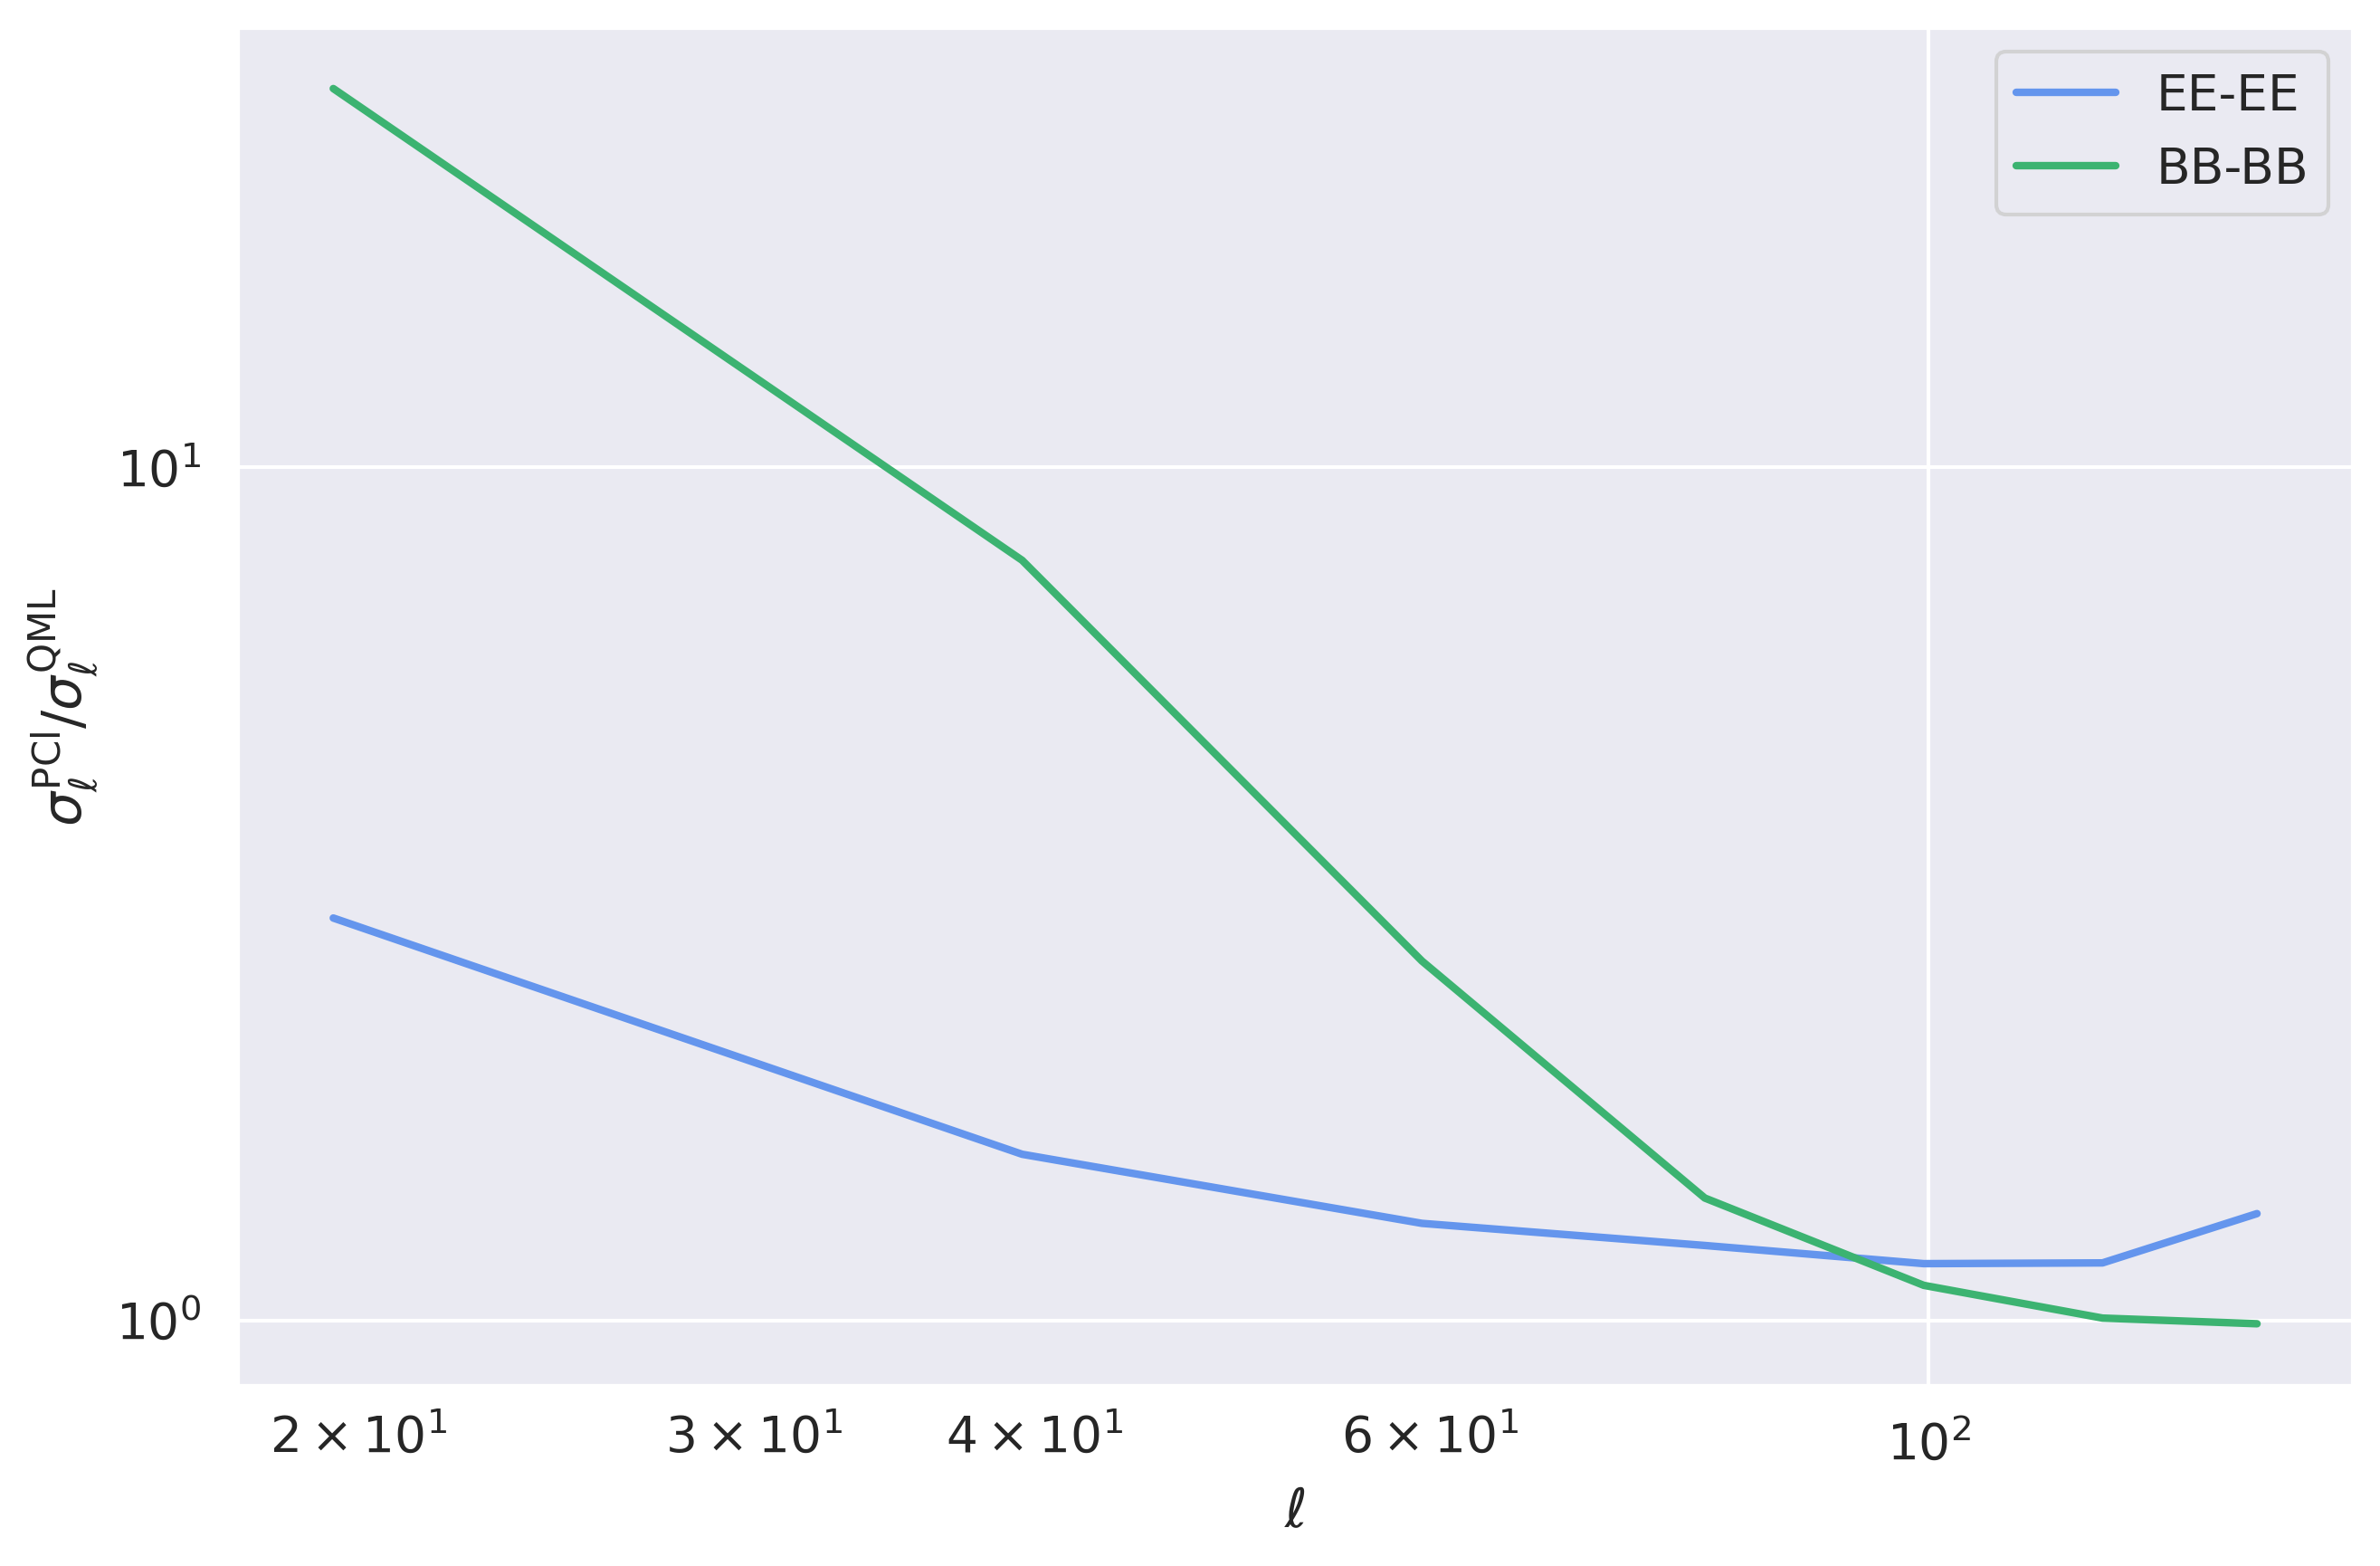

In [26]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.loglog(ell_bp, np.sqrt(np.diag(cov_EE_EE_PCl / cov_EE_EE_QML)), c='cornflowerblue', lw=2, label='EE-EE')
ax.loglog(ell_bp, np.sqrt(np.diag(cov_BB_BB_PCl / cov_BB_BB_QML)), c='mediumseagreen', lw=2, label='BB-BB')

ax.set_xlabel(r'$\ell$')
ax.set_ylabel(r'$\sigma_{\ell}^{\mathrm{PCl}} / \sigma_{\ell}^{\mathrm{QML}}$')

ax.legend()
plt.tight_layout()
plt.show()

## Now use the Fisher matrix to estimate the power spectrum of cosmic shear maps

With our Fisher matrix estimated, we can now use this to produce an estimate of the power spectrum for the set of cosmic shear maps that was produced above.

In [27]:
# Filepath to store the y_ell values in
y_ell_output = f'{tr1_data_dir}/y_ell_out_TR1_south_N{n_side}_lmax{l_max_full}_maps{num_maps}_cov{coverage_min:g}_nv{noise_var:.4e}.dat'

# Execute the C++ code
cpp_lib.compute_power_spectrum(map_gamma1_path, map_gamma2_path, y_ell_output)

With the $y_{\ell}$ values computed, we can read them in and analyse them here

In [28]:
# Load the y_ell values
y_ell_QML = np.loadtxt(y_ell_output)

# Again, we have to delete any modes corresponding to EB spectra as we can't measure them
y_ell_QML = np.delete(y_ell_QML, np.s_[n_ell_full: 2 * n_ell_full], axis=0)

With our $y_{\ell}$ values and the inverse Fisher matrix, we can now compute estimates for the power spectrum coefficients $C_{\ell}$ for the QML estimator.

In [29]:
# Bin the y_ell values into the same bandpowers before combining with the (already binned) inverse Fisher matrix
y_ell_QML_binned = bin_matrix_EB @ y_ell_QML

cl_QML = inv_fisher_QML @ y_ell_QML_binned

# Extract specific components of the Cl values
cl_EE_QML = cl_QML[0: n_bands]
cl_BB_QML = cl_QML[n_bands: 2 * n_bands]

Now compute the PCl estimation of the power spectrum using NaMaster

In [30]:
field_shear = nmt.NmtField(mask, [map_gamma1, map_gamma2], lmax=bins.lmax)
cl_EE_PCl, cl_BB_PCl = nmt.compute_full_master(field_shear, field_shear, bins)[[0, 3]]

## heracles on the South catalogue

An independent, catalogue-based estimate, using the same approach as `Heracles_vs_NaMaster_comparison.ipynb`. The shear catalogue is mapped directly, all tomographic bins together. The spectrum is decoupled with heracles' own mixing matrices, computed from the weight-map spectrum at 2× resolution, and binned into the **same bandpowers** as QML and NaMaster.

`debias=False`: QML (F⁻¹y without the noise bias $b_\ell$) and NaMaster both keep the shot noise, so heracles has to keep it too for a like-for-like comparison. Its default, `debias=True`, would subtract it.

In [31]:
import heracles.healpy

catalog_she = heracles.FitsCatalog(she_catalog_filepath)
catalog_she.visibility = coverage
she_catalogs = {1: catalog_she}   # all tomographic bins together, labelled as a single sample

mapper = heracles.healpy.HealpixMapper(n_side, l_max_full)
fields_she = {
    'SHE': heracles.Shears(mapper, 'SHE_RA', 'SHE_DEC', '-SHE_E1_CORRECTED', 'SHE_E2_CORRECTED', 'SHE_WEIGHT', mask='WHT'),
    'WHT': heracles.Weights(mapper, 'SHE_RA', 'SHE_DEC', 'SHE_WEIGHT'),
}
data_she = heracles.map_catalogs(fields_she, she_catalogs, parallel=True)
alms_she = heracles.transform(fields_she, data_she)
cls_she = heracles.angular_power_spectra(alms_she, include=[('SHE', 'SHE')], debias=False)
cls_she_binned = heracles.binned(cls_she, ell_bp_edges)

# Mixing matrices from the weight-map power spectrum at 2x resolution
mapper2 = heracles.healpy.HealpixMapper(2 * n_side, 2 * l_max_full)
fields_wht2 = {'WHT': heracles.Weights(mapper2, 'SHE_RA', 'SHE_DEC', 'SHE_WEIGHT')}
data_wht2 = heracles.map_catalogs(fields_wht2, she_catalogs, parallel=True)
cls_wht2 = heracles.angular_power_spectra(heracles.transform(fields_wht2, data_wht2))
mms_she = heracles.mixing_matrices(fields_she, cls_wht2, l1max=l_max_full, l2max=l_max_full, bins=ell_bp_edges)
inv_mms_she = heracles.invert_mixing_matrix(mms_she)
# pass lmax explicitly: for binned input the default would be inferred from the number of bins
cls_she_deconv = heracles.apply_mixing_matrix(cls_she_binned, inv_mms_she, lmax=l_max_full)

she_key = ('SHE', 'SHE', 1, 1)
cl_EE_heracles = bins.bin_cell(np.array(cls_she_deconv[she_key][0, 0])[: bins.lmax + 1])
cl_BB_heracles = bins.bin_cell(np.array(cls_she_deconv[she_key][1, 1])[: bins.lmax + 1])
print('heracles EE bandpowers:', cl_EE_heracles)
print('heracles BB bandpowers:', cl_BB_heracles)

heracles EE bandpowers: [8.89572009e-09 1.20348361e-08 7.20537421e-09 9.59510604e-09
 3.81356459e-09 3.40837462e-09 4.94084255e-09]
heracles BB bandpowers: [5.55108814e-09 1.12020579e-09 1.00054242e-09 8.68467398e-10
 4.67457333e-10 1.31500244e-09 1.32955096e-09]


With our estimates of the power spectrum from our two methods, we can plot their results along with the theory curve that the maps were generated from to see how well they match and compare with each other.

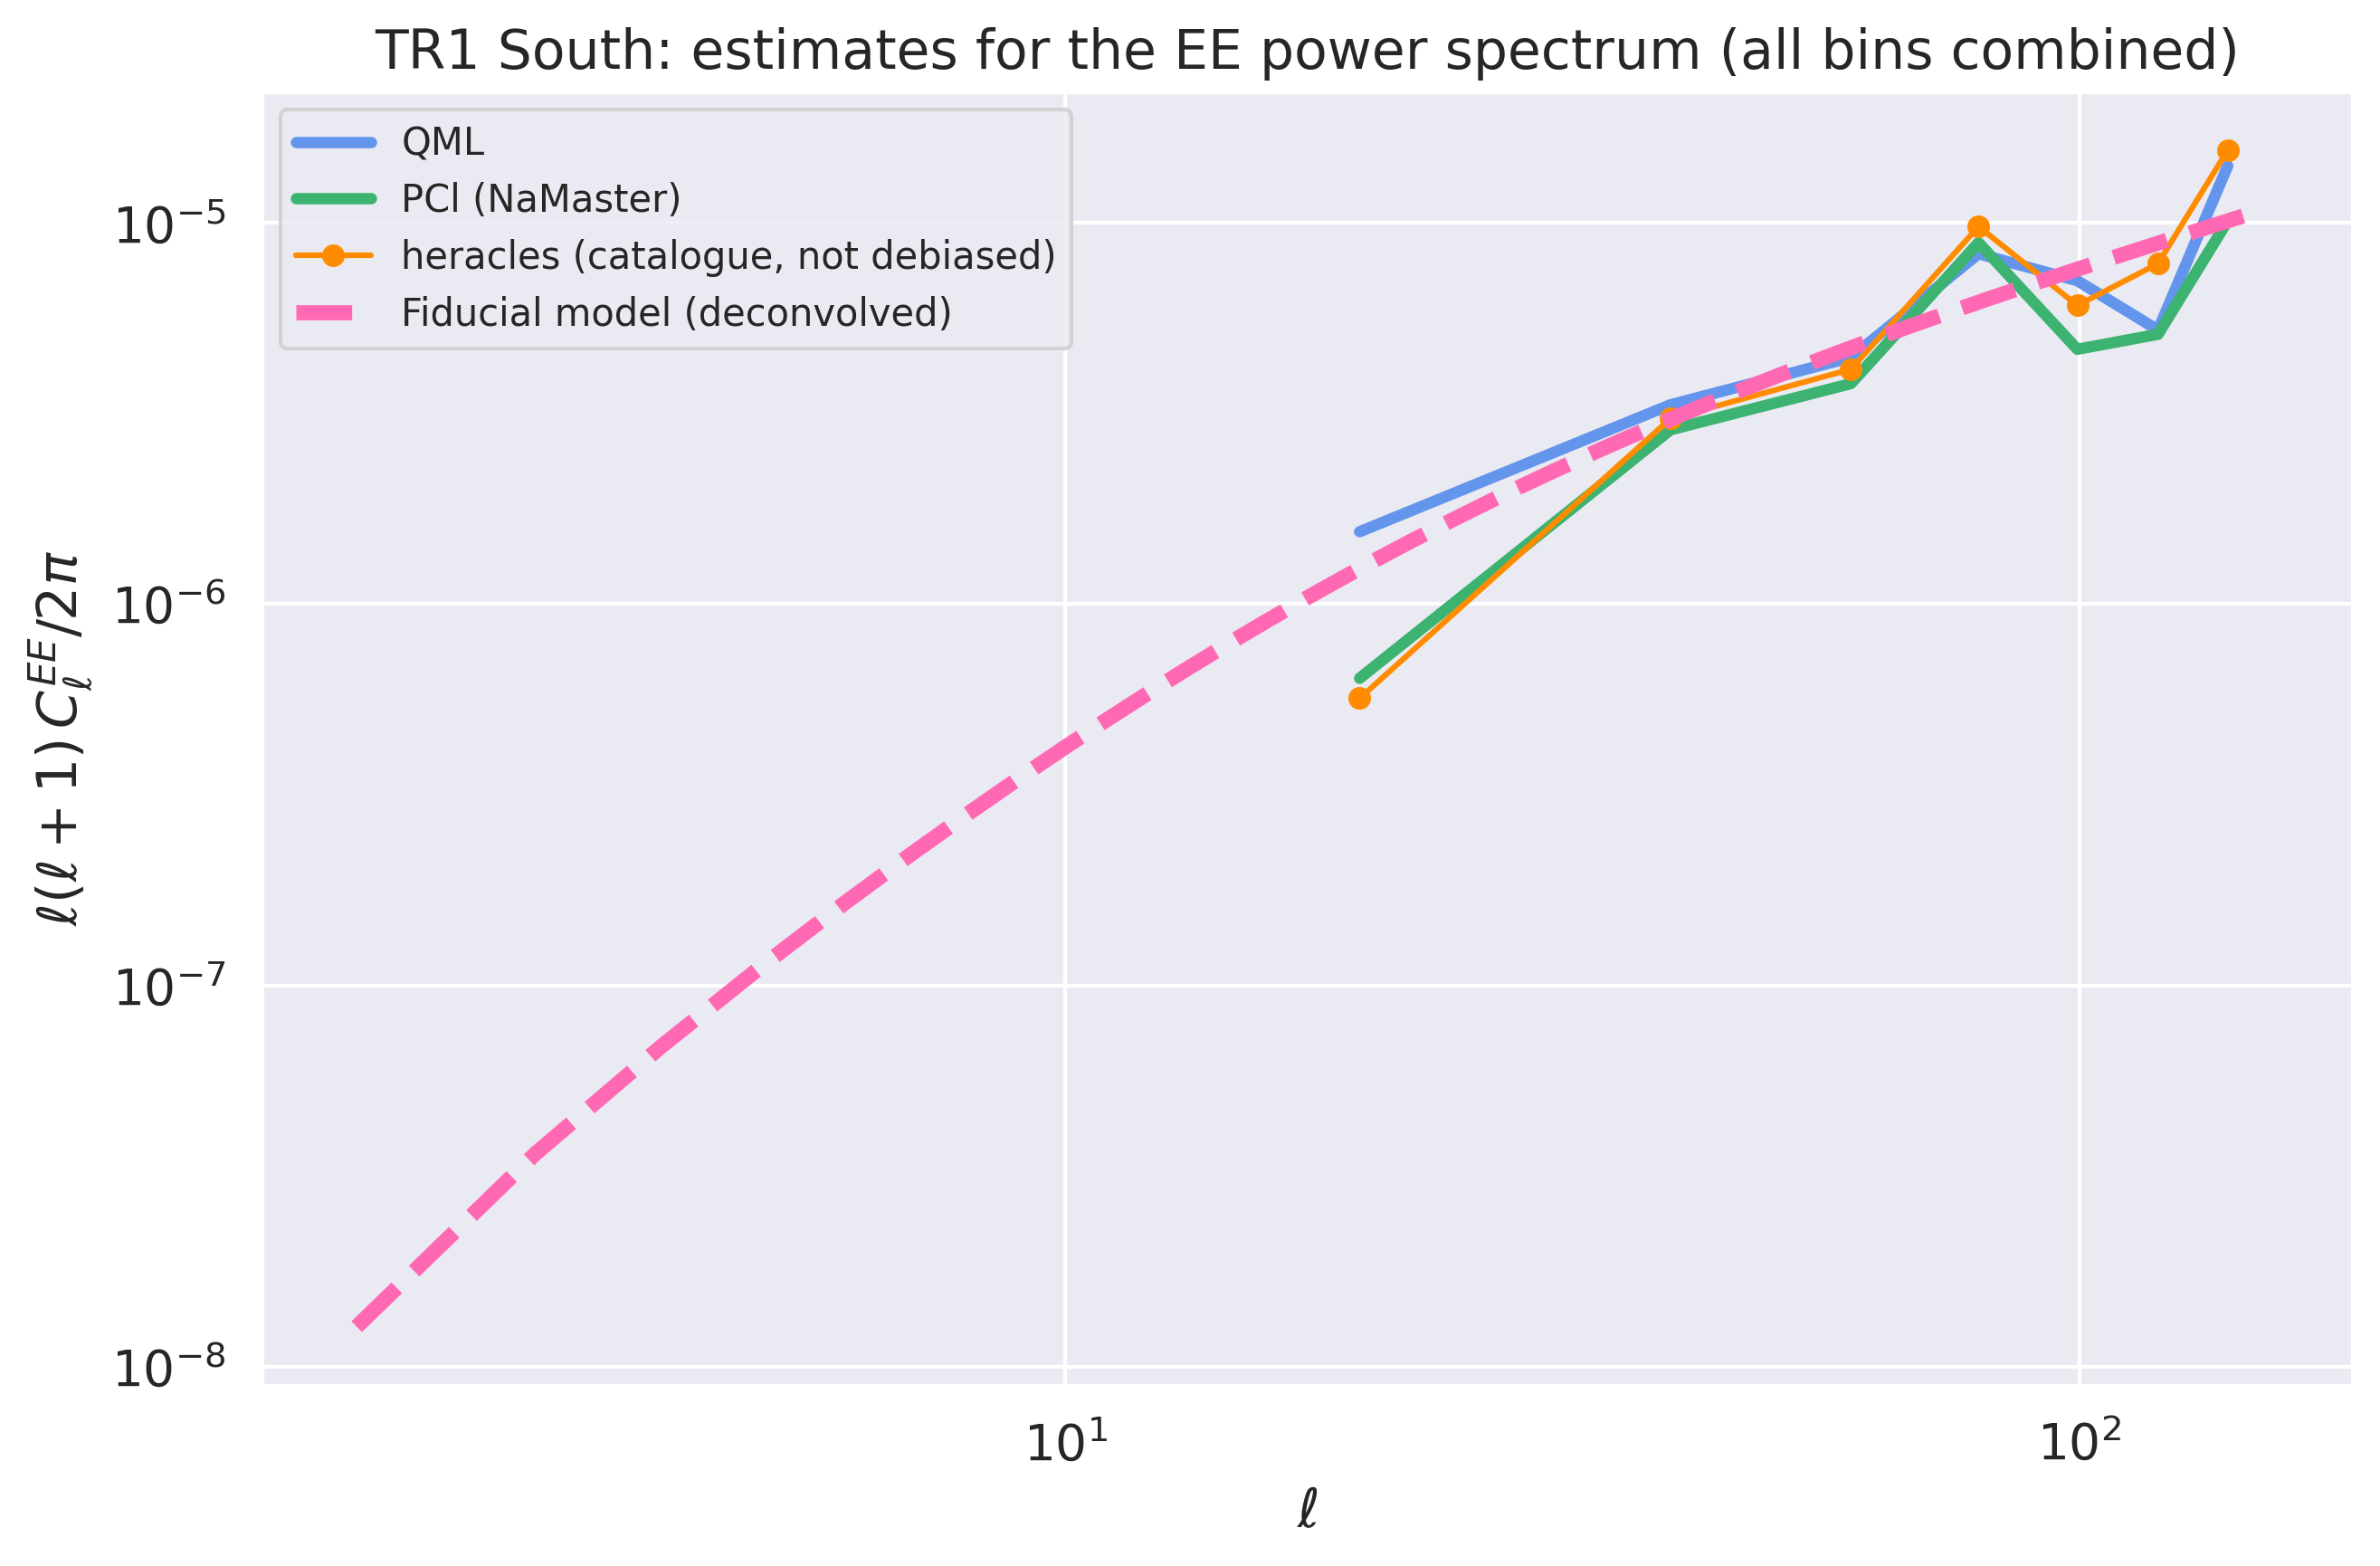

In [32]:
fix, ax = plt.subplots(figsize=(9, 6))

ax.loglog(ell_bp, ell_bp * (ell_bp + 1) * cl_EE_QML / (2 * np.pi), lw=3, c='cornflowerblue', label='QML')
ax.loglog(ell_bp, ell_bp * (ell_bp + 1) * cl_EE_PCl / (2 * np.pi), lw=3, c='mediumseagreen', label='PCl (NaMaster)')
ax.loglog(ell_bp, ell_bp * (ell_bp + 1) * cl_EE_heracles / (2 * np.pi), 'o-', lw=1.5, ms=5, c='darkorange', label='heracles (catalogue, not debiased)')

ax.loglog(ells, ells * (ells + 1) * (pow_spec.cl_EE[2: l_max + 1] + cl_noise) / (2 * np.pi), lw=4, ls='--', c='hotpink', label='Fiducial model (deconvolved)')

ax.set_title('TR1 South: estimates for the EE power spectrum (all bins combined)')
ax.set_xlabel(r'$\ell$')
ax.set_ylabel(r'$\ell (\ell + 1) \, C_{\ell}^{EE} / 2 \pi$')

ax.legend(loc='upper left', fontsize='x-small')

plt.tight_layout()
plt.show()

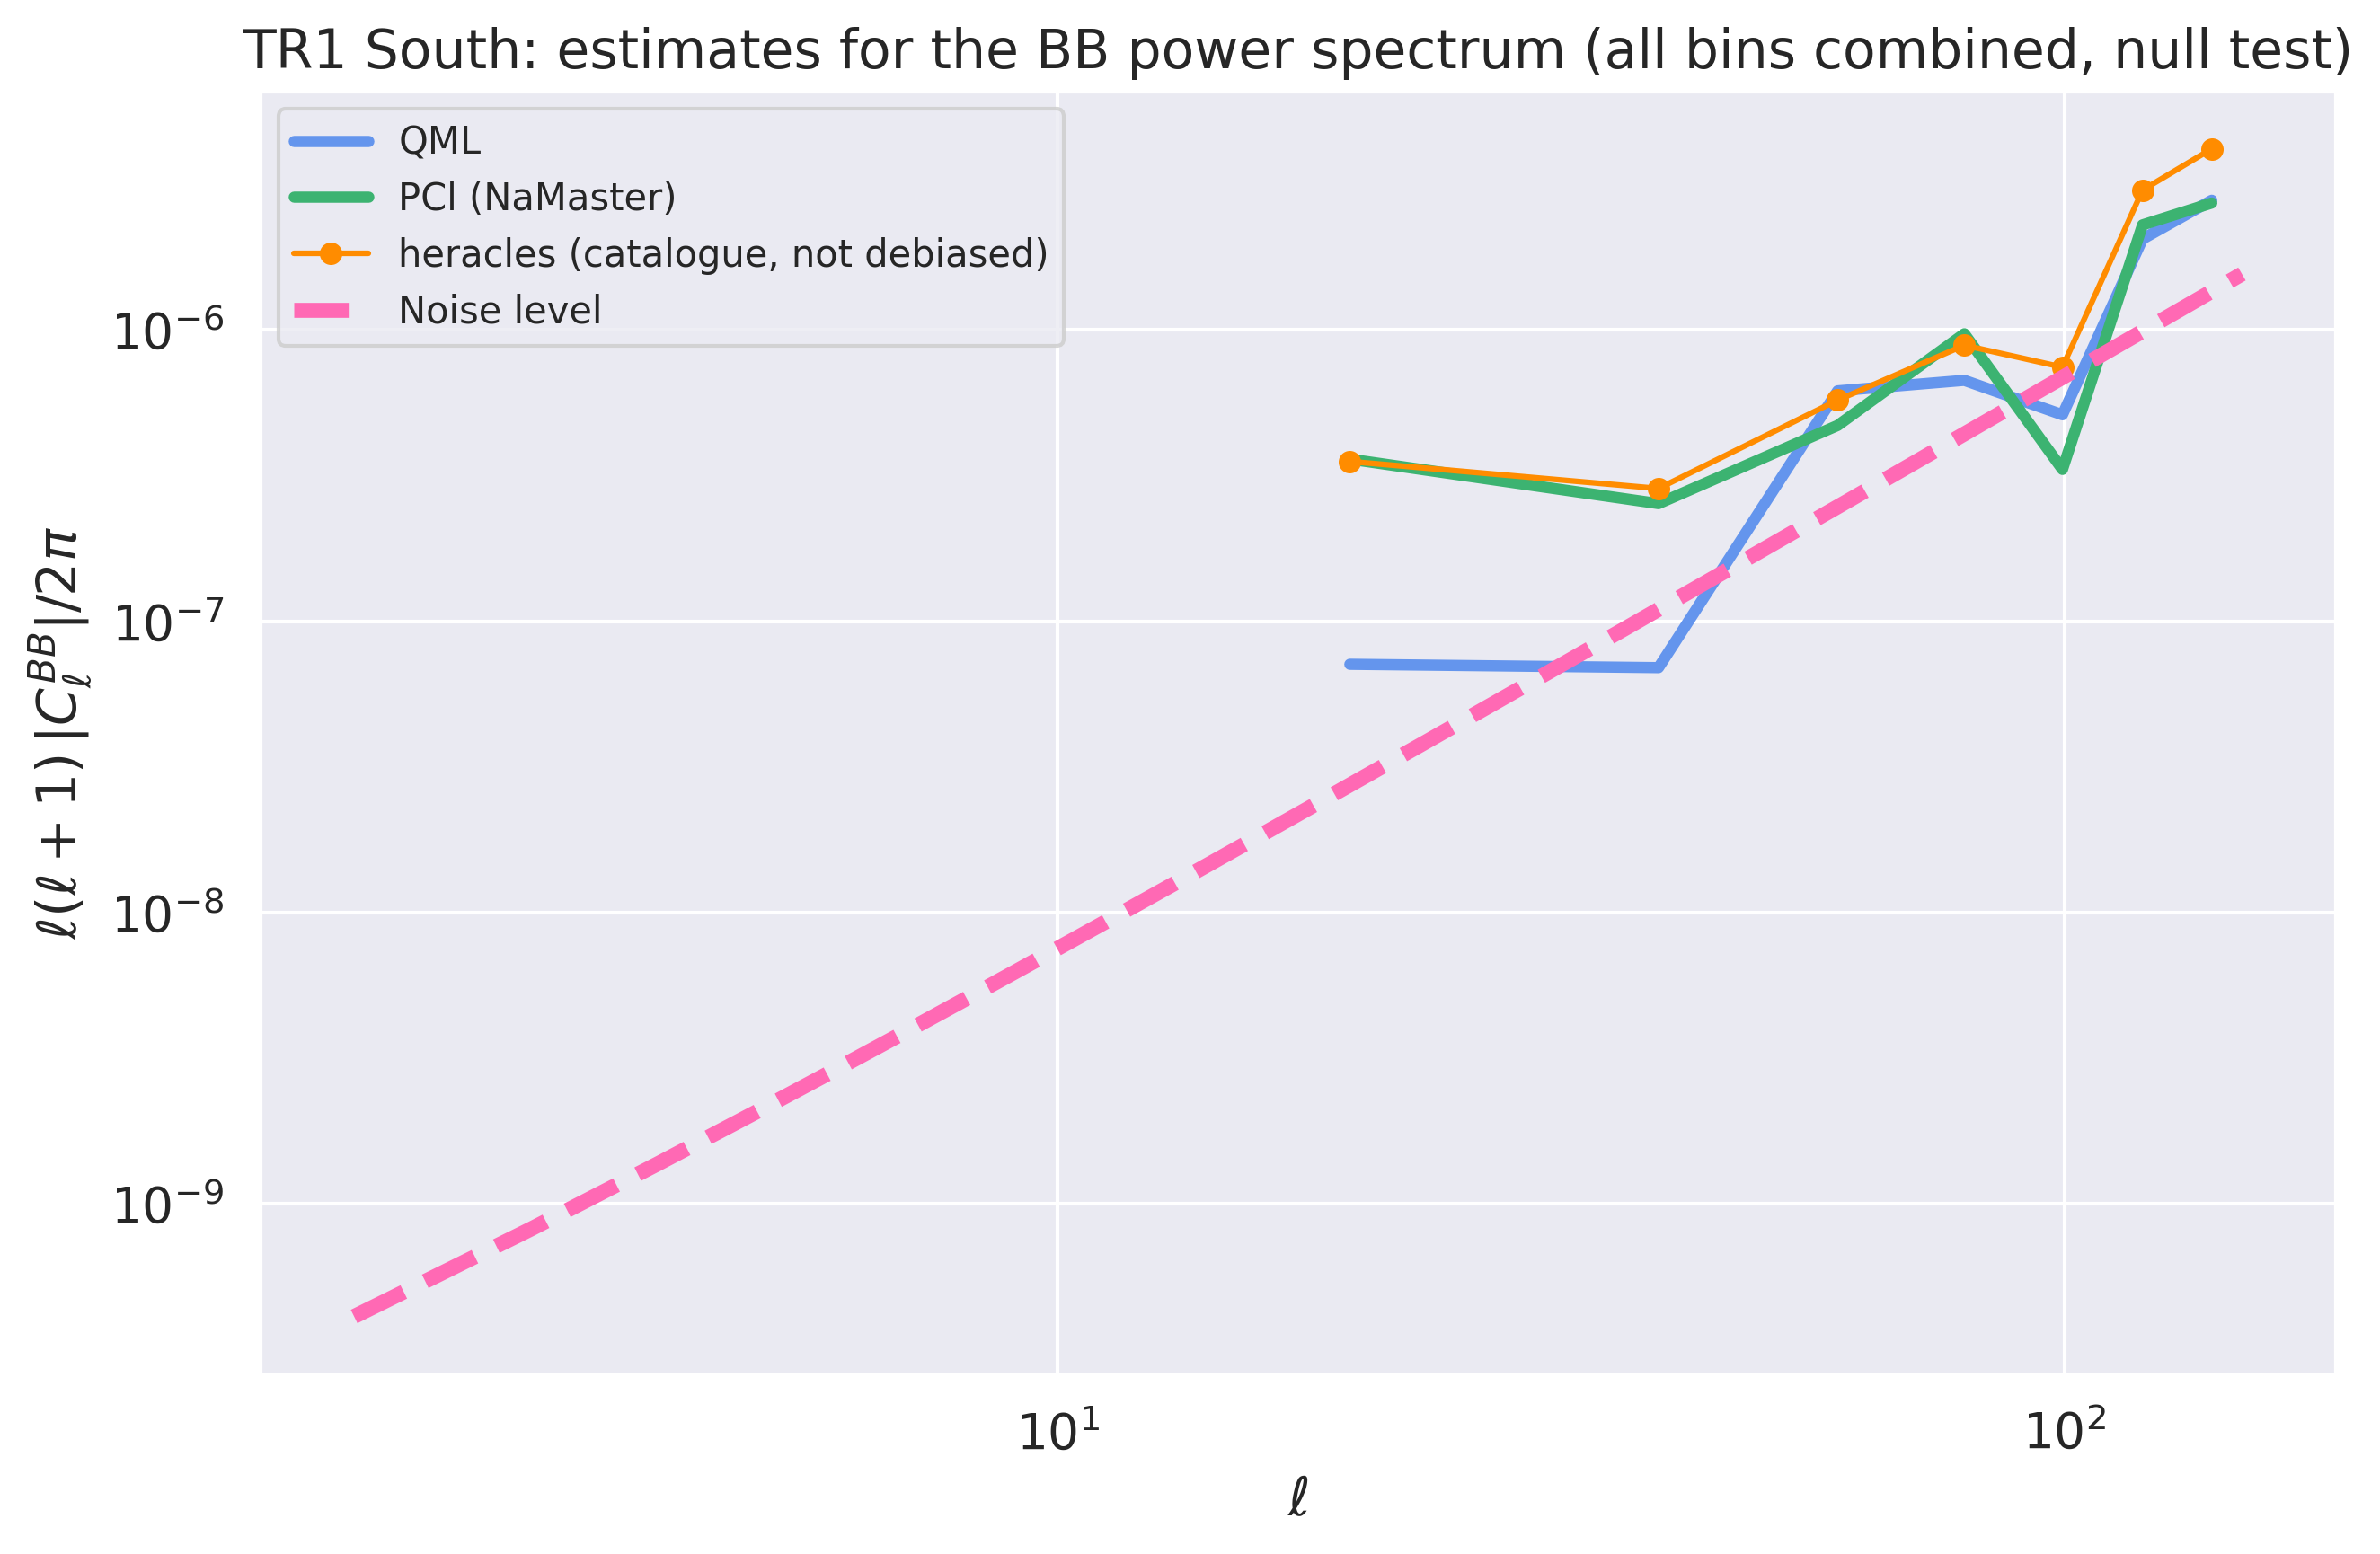

In [33]:
fix, ax = plt.subplots(figsize=(9, 6))

ax.loglog(ell_bp, ell_bp * (ell_bp + 1) * np.abs(cl_BB_QML) / (2 * np.pi), lw=3, c='cornflowerblue', label='QML')
ax.loglog(ell_bp, ell_bp * (ell_bp + 1) * np.abs(cl_BB_PCl) / (2 * np.pi), lw=3, c='mediumseagreen', label='PCl (NaMaster)')
ax.loglog(ell_bp, ell_bp * (ell_bp + 1) * np.abs(cl_BB_heracles) / (2 * np.pi), 'o-', lw=1.5, ms=5, c='darkorange', label='heracles (catalogue, not debiased)')

ax.loglog(ells, ells * (ells + 1) * cl_noise / (2 * np.pi), lw=4, ls='--', c='hotpink', label='Noise level')

ax.set_title('TR1 South: estimates for the BB power spectrum (all bins combined, null test)')
ax.set_xlabel(r'$\ell$')
ax.set_ylabel(r'$\ell (\ell + 1) \, |C_{\ell}^{BB}| / 2 \pi$')

ax.legend(loc='upper left', fontsize='x-small')

plt.tight_layout()
plt.show()

The plots above compare three estimates of the same South data: QML, NaMaster (PCl) on the same mask and map, and heracles run on the catalogue, all with shot noise kept. The dashed line is the fiducial model used to precondition QML. QML, NaMaster and heracles agreeing is the main correctness check. On a patch this small, expect the BB null test to show the largest differences at low ℓ, where E→B leakage and mode coupling are strongest.

In [34]:
print('Bandpower edges [ini, end):', list(zip(ell_bp_ini, ell_bp_end)))
print('Effective (weighted) bandpower centres:', ell_bp)
print('Modes in each bandpower:', [modes_per_ell[(ells_for_binning >= lo) & (ells_for_binning < hi)].sum()
                                     for lo, hi in zip(ell_bp_ini, ell_bp_end)])


Bandpower edges [ini, end): [(np.int64(10), np.int64(30)), (np.int64(30), np.int64(50)), (np.int64(50), np.int64(70)), (np.int64(70), np.int64(90)), (np.int64(90), np.int64(110)), (np.int64(110), np.int64(130)), (np.int64(130), np.int64(151))]
Effective (weighted) bandpower centres: [ 19.5  39.5  59.5  79.5  99.5 119.5 140. ]
Modes in each bandpower: [np.float64(7.194010416666667), np.float64(14.388020833333334), np.float64(21.58203125), np.float64(28.776041666666668), np.float64(35.970052083333336), np.float64(43.16406250000001), np.float64(53.0648193359375)]


In [35]:
n_modes_per_bin = np.array([modes_per_ell[(ells_for_binning >= lo) & (ells_for_binning < hi)].sum()
                            for lo, hi in zip(ell_bp_ini, ell_bp_end)])

# Rule-of-thumb fractional sample-variance scatter for a bin with N independent modes
rule_of_thumb_frac_err = np.sqrt(2 / n_modes_per_bin)

sigma_QML = np.sqrt(np.diag(cov_EE_EE_QML))
sigma_PCl = np.sqrt(np.diag(cov_EE_EE_PCl))

print('Modes/bin:                 ', np.round(n_modes_per_bin, 1))
print('Rule-of-thumb sigma/Cl:    ', np.round(rule_of_thumb_frac_err, 3))
# Divide by the binned theory (signal + noise): dividing by the measured bandpower, which is itself noisy,
# gives misleading (even negative) ratios
cl_theory_binned = bins.bin_cell(pow_spec.cl_EE[: bins.lmax + 1]) + cl_noise
print('QML sigma/(theory S+N):    ', np.round(sigma_QML / cl_theory_binned, 3))
print('PCl sigma/(theory S+N):    ', np.round(sigma_PCl / cl_theory_binned, 3))


Modes/bin:                  [ 7.2 14.4 21.6 28.8 36.  43.2 53.1]
Rule-of-thumb sigma/Cl:     [0.527 0.373 0.304 0.264 0.236 0.215 0.194]
QML sigma/(theory S+N):     [0.448 0.379 0.336 0.299 0.277 0.25  0.191]
PCl sigma/(theory S+N):     [1.327 0.594 0.436 0.366 0.323 0.292 0.254]


## Effect of the coverage cut on QML and heracles

The two estimators handle partly covered pixels very differently:
- **QML** uses a binary mask and assumes **one noise variance for every pixel**. A partly covered pixel with few galaxies is far noisier than assumed, which biases the estimate.
- **heracles** doesn't use the binary mask. It works from the catalogue's galaxy weights, with the **fractional coverage** map as its visibility, so partly covered pixels are naturally down-weighted.

This section compares both estimators **without the cut** (every pixel with any coverage) and **with it** (`coverage >= coverage_min`), on the same 20-wide bandpowers:
- **QML without the cut** reuses the Fisher matrix and $y_\ell$ cached by the first run with `coverage > 0` (files without a `_cov` tag). It's re-binned here, so no new Fisher run is needed. **QML with the cut** is the result computed above.
- **heracles without the cut** is the full catalogue with the fractional coverage as visibility. **heracles with the cut** uses only the galaxies in kept pixels, with the visibility set to zero outside them.

To compare like with like, both heracles versions are **debiased** (shot noise subtracted). For QML each version's own *modelled* noise is subtracted. So EE is compared with the **signal** theory, and BB with **zero**. Error bars are QML's from its binned Fisher matrix.

In [36]:
def qml_bandpowers(fisher_file, y_file, noise_var_model):
    # Binned QML estimate from a per-ell Fisher matrix and y_ell (same steps as above); returns signal-only
    # EE and BB bandpowers (modelled noise subtracted) and their covariance
    F = np.loadtxt(fisher_file)
    F = np.delete(np.delete(F, np.s_[n_ell_full: 2 * n_ell_full], axis=0), np.s_[n_ell_full: 2 * n_ell_full], axis=1)
    F = (F + F.T) / 2
    y = np.delete(np.loadtxt(y_file), np.s_[n_ell_full: 2 * n_ell_full], axis=0)
    cov = np.linalg.inv(bin_matrix_EB @ F @ bin_matrix_EB.T)
    c = cov @ (bin_matrix_EB @ y)
    N_model = noise_var_model * 4 * np.pi / n_pix          # the white noise level QML's covariance assumes
    return c[:n_bands] - N_model, c[n_bands:] - N_model, cov


def heracles_bandpowers(catalog_file, visibility):
    # heracles on a catalogue, debiased (signal only), decoupled with its own mixing matrices, same bandpowers
    cat = heracles.FitsCatalog(catalog_file)
    cat.visibility = visibility
    cats = {1: cat}
    mapper = heracles.healpy.HealpixMapper(n_side, l_max_full)
    fields = {
        'SHE': heracles.Shears(mapper, 'SHE_RA', 'SHE_DEC', '-SHE_E1_CORRECTED', 'SHE_E2_CORRECTED', 'SHE_WEIGHT', mask='WHT'),
        'WHT': heracles.Weights(mapper, 'SHE_RA', 'SHE_DEC', 'SHE_WEIGHT'),
    }
    cls = heracles.angular_power_spectra(heracles.transform(fields, heracles.map_catalogs(fields, cats, parallel=True)),
                                         include=[('SHE', 'SHE')], debias=True)
    mapper2 = heracles.healpy.HealpixMapper(2 * n_side, 2 * l_max_full)
    fields2 = {'WHT': heracles.Weights(mapper2, 'SHE_RA', 'SHE_DEC', 'SHE_WEIGHT')}
    cls2 = heracles.angular_power_spectra(heracles.transform(fields2, heracles.map_catalogs(fields2, cats, parallel=True)))
    mms = heracles.mixing_matrices(fields, cls2, l1max=l_max_full, l2max=l_max_full, bins=ell_bp_edges)
    deconv = heracles.apply_mixing_matrix(heracles.binned(cls, ell_bp_edges), heracles.invert_mixing_matrix(mms), lmax=l_max_full)
    key = ('SHE', 'SHE', 1, 1)
    return (bins.bin_cell(np.array(deconv[key][0, 0])[: bins.lmax + 1]),
            bins.bin_cell(np.array(deconv[key][1, 1])[: bins.lmax + 1]))

In [37]:
# --- QML without the cut: cached first run (coverage > 0). Its noise_var used all galaxies over all covered pixels.
covered = coverage > 0
w_all = she_weight
sigma_e2_all = np.sum(w_all * (she_e1 ** 2 + she_e2 ** 2)) / (2 * np.sum(w_all))
noise_var_nocut = sigma_e2_all / ((np.sum(w_all) ** 2 / np.sum(w_all ** 2)) / covered.sum())
qml_nocut = qml_bandpowers(f'{tr1_data_dir}/Fisher_matrix_TR1_south_N{n_side}_lmax{l_max_full}_maps{num_maps}.dat',
                           f'{tr1_data_dir}/y_ell_out_TR1_south_N{n_side}_lmax{l_max_full}_maps{num_maps}.dat', noise_var_nocut)
# --- QML with the cut: the result computed above
qml_cut = qml_bandpowers(fisher_matrix_out, y_ell_output, noise_var)

# --- heracles without the cut: full catalogue, fractional coverage as visibility
her_nocut = heracles_bandpowers(she_catalog_filepath, coverage)
# --- heracles with the cut: galaxies in kept pixels only, visibility zero outside them
kept_catalog = f'{tr1_data_dir}/catalogue_kept_cov{coverage_min:g}.fits'
if not os.path.exists(kept_catalog):
    keep = mask[hp.ang2pix(n_side, she_data['SHE_RA'], she_data['SHE_DEC'], lonlat=True)]
    fitsio.write(kept_catalog, she_data[['SHE_RA', 'SHE_DEC', 'SHE_E1_CORRECTED', 'SHE_E2_CORRECTED', 'SHE_WEIGHT']][keep],
                 clobber=True)
her_cut = heracles_bandpowers(kept_catalog, coverage * mask)

theory_signal_b = bins.bin_cell(pow_spec.cl_EE[: bins.lmax + 1])
for label, (EE, BB, cov) in [('QML, no cut', qml_nocut), (f'QML, cut >= {coverage_min:g}', qml_cut)]:
    dE, dB = EE - theory_signal_b, BB
    x2E = dE @ np.linalg.solve(cov[:n_bands, :n_bands], dE)
    x2B = dB @ np.linalg.solve(cov[n_bands:, n_bands:], dB)
    print(f'{label:<18} EE vs signal theory: chi2 = {x2E:7.1f} / {n_bands};   BB null test: chi2 = {x2B:7.1f} / {n_bands}')

QML, no cut        EE vs signal theory: chi2 = 13406.7 / 7;   BB null test: chi2 = 32228.4 / 7
QML, cut >= 0.5    EE vs signal theory: chi2 =     7.7 / 7;   BB null test: chi2 =    50.4 / 7


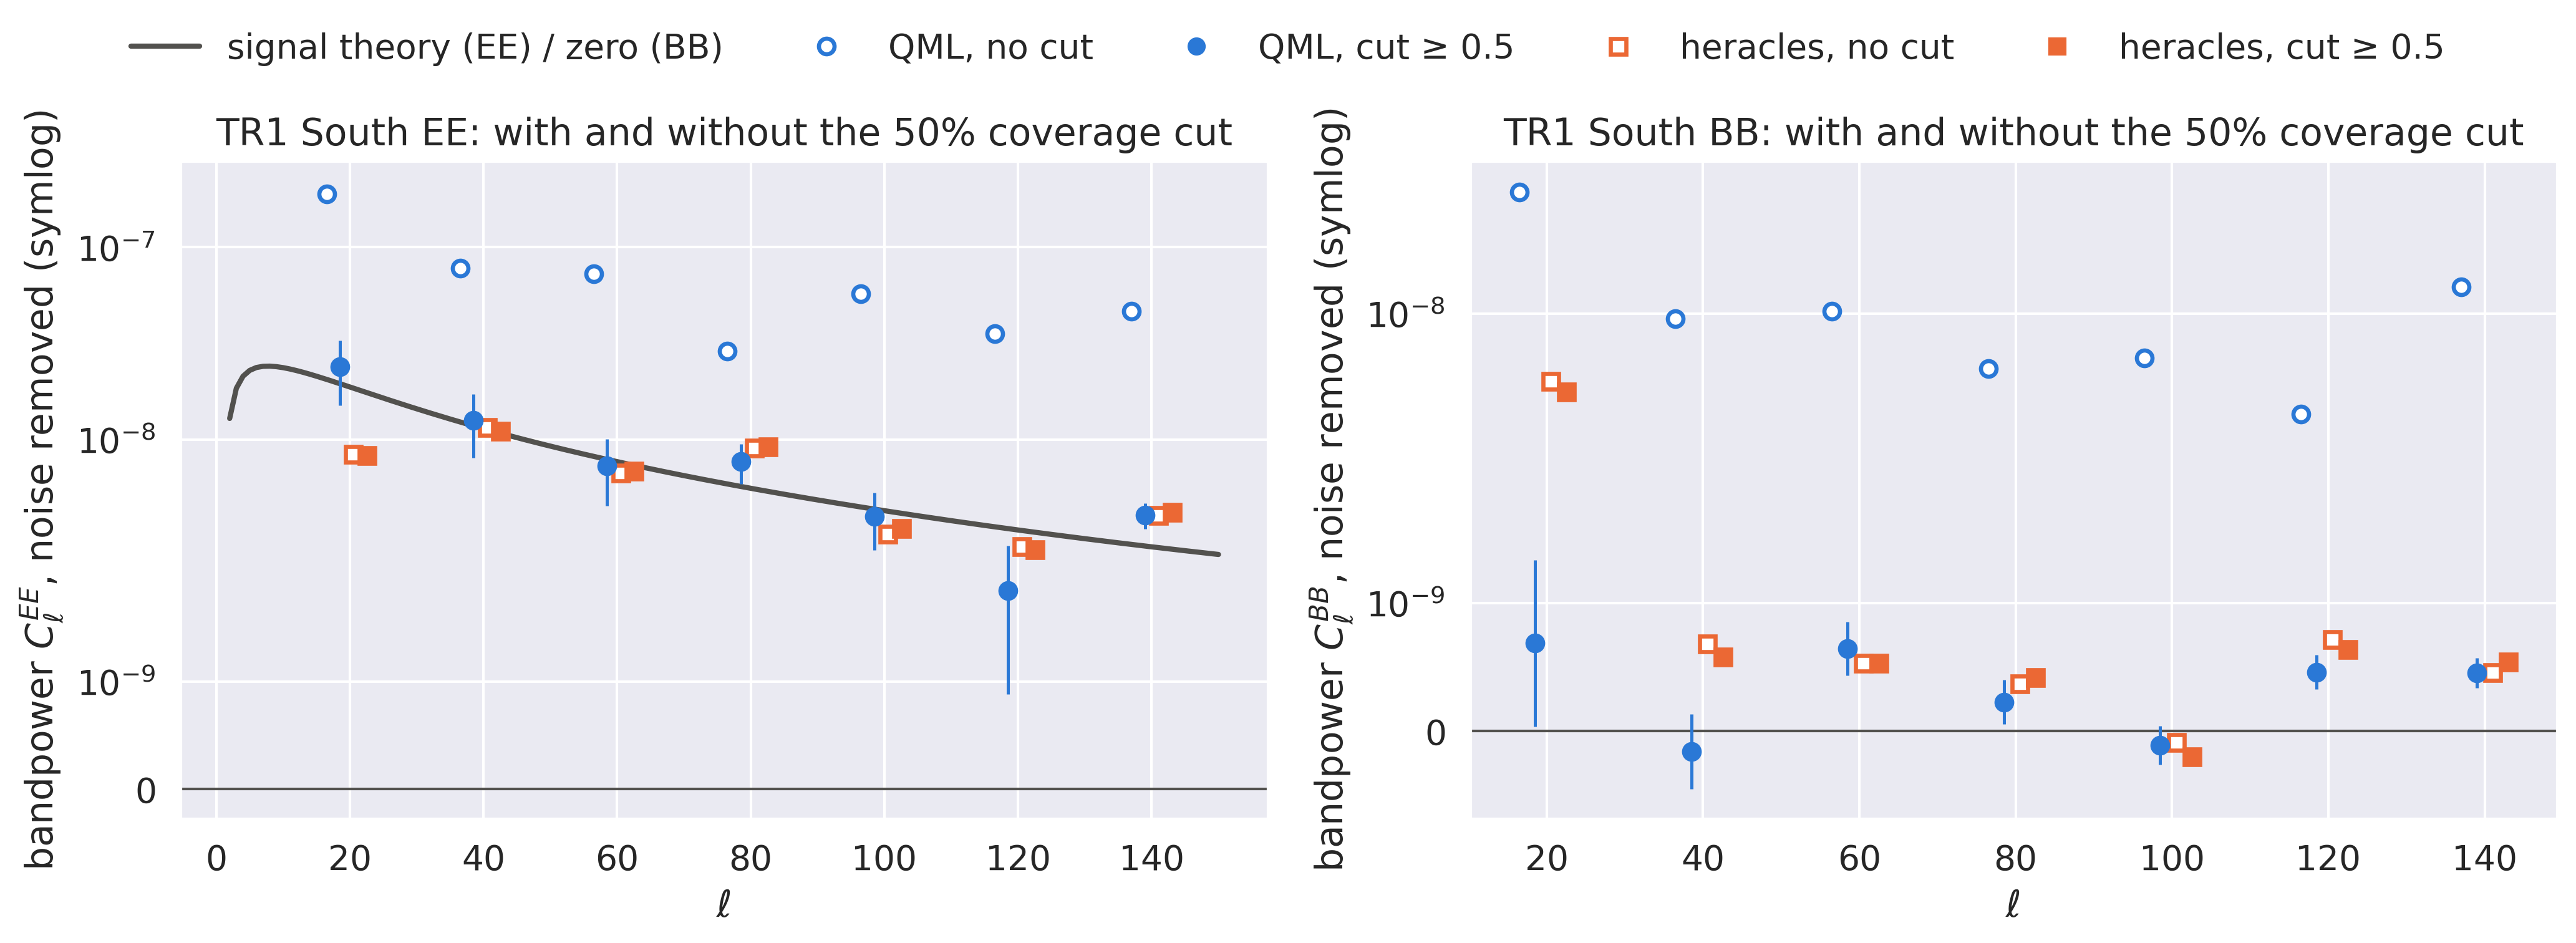

In [38]:
from matplotlib.lines import Line2D

BLUE, ORANGE, INK = '#2a78d6', '#eb6834', '#52514e'
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
dx = 2.0
for ax, idx, spec in [(axes[0], 0, 'EE'), (axes[1], 1, 'BB')]:
    if spec == 'EE':
        ax.plot(ells, pow_spec.cl_EE[ells], color=INK, lw=2, zorder=1)
    ax.axhline(0, color=INK, lw=1, zorder=1)
    for (EE, BB, cov), filled, shift in [(qml_nocut, False, -1.5 * dx), (qml_cut, True, -0.5 * dx)]:
        vals = (EE, BB)[idx]
        sig = np.sqrt(np.abs(np.diag(cov)))[idx * n_bands: (idx + 1) * n_bands]
        ax.errorbar(ell_bp + shift, vals, sig, fmt='o', ms=6, color=BLUE, mfc=BLUE if filled else 'white',
                    mew=1.6, elinewidth=1.2, capsize=0, zorder=3)
    for vals2, filled, shift in [(her_nocut, False, 0.5 * dx), (her_cut, True, 1.5 * dx)]:
        ax.plot(ell_bp + shift, vals2[idx], 's', ms=6, color=ORANGE, mfc=ORANGE if filled else 'white', mew=1.6, zorder=3)
    ax.set_yscale('symlog', linthresh=2e-9, linscale=1.0)
    ax.set_xlabel('ℓ')
    ax.set_ylabel(f'bandpower $C_\\ell^{{{spec}}}$, noise removed (symlog)')
    ax.set_title(f'TR1 South {spec}: with and without the {100 * coverage_min:.0f}% coverage cut')
handles = [Line2D([], [], color=INK, lw=2, label='signal theory (EE) / zero (BB)'),
           Line2D([], [], marker='o', ls='', color=BLUE, mfc='white', mew=1.6, label='QML, no cut'),
           Line2D([], [], marker='o', ls='', color=BLUE, label=f'QML, cut ≥ {coverage_min:g}'),
           Line2D([], [], marker='s', ls='', color=ORANGE, mfc='white', mew=1.6, label='heracles, no cut'),
           Line2D([], [], marker='s', ls='', color=ORANGE, label=f'heracles, cut ≥ {coverage_min:g}')]
fig.legend(handles=handles, loc='upper center', ncol=5, bbox_to_anchor=(0.5, 1.03), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Reading the plot:** filled markers are with the cut, open markers without it.
- If **QML moves a lot between open and filled while heracles barely moves**, the problem was QML's uniform-noise assumption, not the data near the edges: heracles' coverage weighting already copes with partly covered pixels.
- If **heracles also changes**, the edge pixels carry something genuinely different (for example, systematics near the survey boundary), and the coverage cut matters for any estimator.

## Save a results summary

All key arrays in one file, `TR1/data/south/results_summary_*.npz`, so reports and plots can be made without re-running this notebook.

In [39]:
summary_path = f'{tr1_data_dir}/results_summary_N{n_side}_lmax{l_max_full}_maps{num_maps}_cov{coverage_min:g}.npz'
np.savez(
    summary_path,
    n_side=n_side, l_max_full=l_max_full, num_maps=num_maps, coverage_min=coverage_min, f_sky=f_sky,
    n_pix_mask=mask.sum(), density_arcmin2=avg_gal_den, sigma_e=np.sqrt(sigma_e2), noise_var=noise_var, cl_noise=cl_noise,
    ell_bp=ell_bp, ell_bp_edges=ell_bp_edges, ells=ells, cl_EE_theory=pow_spec.cl_EE,
    cl_EE_QML=cl_EE_QML, cl_BB_QML=cl_BB_QML, cov_QML=inv_fisher_QML,
    cl_EE_PCl=cl_EE_PCl, cl_BB_PCl=cl_BB_PCl, cov_EE_EE_PCl=cov_EE_EE_PCl, cov_BB_BB_PCl=cov_BB_BB_PCl,
    cl_EE_heracles=cl_EE_heracles, cl_BB_heracles=cl_BB_heracles,
    qml_nocut_EE=qml_nocut[0], qml_nocut_BB=qml_nocut[1], qml_nocut_cov=qml_nocut[2],
    qml_cut_EE=qml_cut[0], qml_cut_BB=qml_cut[1], qml_cut_cov=qml_cut[2],
    her_nocut_EE=her_nocut[0], her_nocut_BB=her_nocut[1], her_cut_EE=her_cut[0], her_cut_BB=her_cut[1],
    coverage=coverage, mask=mask, noise_ratio=noise_ratio, galaxies_removed=len(w_removed), galaxies_total=len(she_weight),
)
print('saved', summary_path)

saved /home/vscode/WeakLensingQML/TR1/data/south/results_summary_N64_lmax150_maps10_cov0.5.npz
